# Multimodal depression analysis on DAIC-WOZ
**Sessions:** 303 (PHQ-8 binary 0, not depressed) and 319 (PHQ-8 binary 1, depressed). More sessions can be added in one place.

This notebook replaces the earlier one. It analyses the interview text, voice, face, gaze and head movement, trains an LSTM and a BiLSTM on your own text datasets, compares them with three pretrained models, and ends with one cell that produces every figure for the report.

## How to run it
Run Section 1 and Section 2 first. After that every block is independent unless the table says otherwise, so you can run only what you need.

| Block | What it does | Needs |
|---|---|---|
| 1 Setup | libraries, paths, your sessions and training datasets | none |
| 2 Data loading | transcripts, labels, Ellie question for each answer | 1 |
| 3 Behaviour and text preparation | talk time, response delay, key questions and answers, text chunks | 2 |
| 4 Text analysis | tone per turn, wording cues, PHQ-8 symptom evidence | 2 (4.1 and 4.3 need transformers) |
| 5 Voice | COVAREP and formant descriptors, optional speech emotion | 2 |
| 6 Face | action units during speech | 2 |
| 7 Gaze and head | gaze direction and head motion | 2 |
| 8 Fusion | per-minute table and all-session feature table | 2 and any of 3 to 7 |
| 9 Train LSTM and BiLSTM | leakage-safe training on your datasets | 1, 3.3 |
| 10 Pretrained models | DepRoBERTa, RoBERTa sentiment, BART zero-shot | 3.3 |
| 11 Compare on the interviews | five models on 303 and 319 | 9 and 10 |
| 12 Report figures | every figure and table, saved and zipped | whatever you have run |

## What changed compared with the earlier notebook
- The COVAREP columns now follow the AVEC documentation. The old notebook called column 11 `creak`, but it is `MCEP_0`.
- Sentiment is scored per answer, never on a 512-token-truncated whole corpus, and without removing stop words, so negation survives.
- Shares are computed correctly. The old `np.mean([1 for ...])` always returned 1.
- Every answer keeps Ellie's question, and the answers to key questions (diagnosis, sleep, regret) are listed.
- The untrained LSTM cells are gone. Models are trained on your datasets with a train, validation and test split.
- Nothing is z-scored inside a single interview, so sessions can be compared in real units.
- Speech-driven action units and gaps in tracker output are excluded.
- PHQ-8 scores and item scores are joined when you give the split CSV files.

## Leakage rules this notebook follows
1. Duplicates and texts with conflicting labels are removed before any split.
2. If your data has an author or thread column, whole groups stay on one side of the split.
3. The vocabulary is built from the training split only.
4. Early stopping and the decision threshold use the validation split only. The test split is read once for reporting.
5. Any training text that shares an eight-word sequence with a 303 or 319 interview chunk is dropped.
6. The two interviews are never used for training, tuning or choosing a threshold. Pretrained models use a fixed threshold of one half.
7. The verdict rule (mean probability against the threshold) is fixed before looking at the interview scores.

# 1. Setup and configuration
Edit only this block when you change sessions, folders or datasets.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
ROOT = Path("/content/drive/MyDrive/Multimodal_CEDS")
print(ROOT.exists())
for p in sorted(ROOT.iterdir())[:30]:
    print(p.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True
303_P.zip
319_P.zip
320_P.zip
321_P.zip
325_P.zip
330_P.zip
338_P.zip
485_P.zip
486_P.zip
487_P.zip
488_P.zip
491_P.zip
dev_split_Depression_AVEC2017.csv
full_test_split.csv
test_split_Depression_AVEC2017.csv
train_split_Depression_AVEC2017.csv


In [27]:
# UNZIP EVERY SESSION ZIP FROM DRIVE INTO ITS OWN FOLDER ON THE COLAB DISK
import zipfile
from pathlib import Path

SRC = Path("/content/drive/MyDrive/Multimodal_CEDS")
DST = Path("/content/daic")
DST.mkdir(exist_ok=True)

for zpath in sorted(SRC.glob("*.zip")):
    target = DST / zpath.stem
    if target.exists() and any(target.iterdir()):
        print("Already extracted:", zpath.stem)
        continue
    with zipfile.ZipFile(zpath) as z:
        names = [n for n in z.namelist() if not n.startswith("__MACOSX")]
        has_root = all(n.startswith(zpath.stem + "/") for n in names)
        z.extractall(DST if has_root else target, members=names)
    print("Extracted:", zpath.stem, "->", target)

print(sorted(p.name for p in DST.iterdir()))

Extracted: 303_P -> /content/daic/303_P
Extracted: 319_P -> /content/daic/319_P
Extracted: 320_P -> /content/daic/320_P
Extracted: 321_P -> /content/daic/321_P
Extracted: 325_P -> /content/daic/325_P
Extracted: 330_P -> /content/daic/330_P
Extracted: 338_P -> /content/daic/338_P
Extracted: 485_P -> /content/daic/485_P
Extracted: 486_P -> /content/daic/486_P
Extracted: 487_P -> /content/daic/487_P
Extracted: 488_P -> /content/daic/488_P
Extracted: 491_P -> /content/daic/491_P
['303_AUDIO.wav', '303_CLNF_AUs.txt', '303_CLNF_features.txt', '303_CLNF_features3D.txt', '303_CLNF_gaze.txt', '303_CLNF_hog.bin', '303_CLNF_pose.txt', '303_COVAREP.csv', '303_FORMANT.csv', '303_P', '303_TRANSCRIPT.csv', '319_AUDIO.wav', '319_CLNF_AUs.txt', '319_CLNF_features.txt', '319_CLNF_features3D.txt', '319_CLNF_gaze.txt', '319_CLNF_hog.bin', '319_CLNF_pose.txt', '319_COVAREP.csv', '319_FORMANT.csv', '319_P', '319_TRANSCRIPT.csv', '320_P', '321_P', '325_P', '330_P', '338_P', '485_P', '486_P', '487_P', '488_P'

In [30]:
# SETUP, CONFIGURATION AND SHARED HELPERS
import re, random, json, zipfile, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


set_seed()

# ---- Sessions to analyse and their PHQ-8 binary label (zero is not depressed, one is depressed).
SESSIONS = {303: 0, 319: 1}
BASE_DIR_TEMPLATE = "/content/daic/{sid}_P"
FILE_PATTERNS = {
    "transcript": "{sid}_TRANSCRIPT.csv",
    "aus": "{sid}_CLNF_AUs.txt",
    "gaze": "{sid}_CLNF_gaze.txt",
    "pose": "{sid}_CLNF_pose.txt",
    "covarep": "{sid}_COVAREP.csv",
    "formant": "{sid}_FORMANT.csv",
    "audio": "{sid}_AUDIO.wav",
}


LABEL_FILES = [
    "/content/drive/MyDrive/Multimodal_CEDS/train_split_Depression_AVEC2017.csv",
    "/content/drive/MyDrive/Multimodal_CEDS/dev_split_Depression_AVEC2017.csv",
    "/content/drive/MyDrive/Multimodal_CEDS/full_test_split.csv",
]


TRAIN_SOURCES = [
    {"daic_dir": "/content/daic",
     "daic_ids": [320, 321, 325, 330, 338, 485, 486, 487, 488, 491,
                    339,
                    344,
                    345,
                    347,
                    348,
                    350,
                    351,
                    352,
                    353,
                    355,
                    457,
                    463,
                    464,
                    468,
                    471,
                    473,
                    474,
                    475,
                    478,
                    479],
     "label_files": LABEL_FILES},
]
# ---- Analysis settings.
CHUNK_WORDS = 60
MIN_CHUNK_WORDS = 20
TONE_MIN_WORDS = 4
SYMPTOM_MIN_WORDS = 8
SHORT_TURN_WORDS = 3
LATENCY_MAX_SEC = 10.0
WINDOW_SEC = 60
F0_MIN, F0_MAX = 60.0, 400.0
FACE_CONF_MIN = 0.8
AU_ON = 1.0
FRONTAL_DEG = 10.0
FRAME_GAP_MAX = 0.1
SPEECH_AUS = ["AU10_r", "AU14_r", "AU17_r", "AU20_r", "AU25_r", "AU26_r"]
AU_KEEP = ["AU01_r", "AU02_r", "AU04_r", "AU05_r", "AU06_r", "AU09_r", "AU12_r", "AU15_r"]
RUN_SPEECH_EMOTION = True
RUN_SYMPTOMS = True

# ---- Training settings for the recurrent models.
MAX_TOKENS = 80
BATCH_SIZE = 64
EPOCHS = 15
PATIENCE = 3
LEARNING_RATE = 1e-3

FIG_DIR = Path("/content/report_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
LABEL_COLORS = {0: "#1D7A85", 1: "#B5501A"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# Shared stores that later blocks fill in.
FEATURES = {sid: {} for sid in SESSIONS}
FIG_FUNCS = {}


def path_of(sid, key):
    return Path(BASE_DIR_TEMPLATE.format(sid=sid)) / FILE_PATTERNS[key].format(sid=sid)


def sess_label(sid):
    return f"{sid} ({'depressed' if SESSIONS[sid] else 'not depressed'}")


def require(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError("Run the blocks that create " + ", ".join(missing) + " first.")


def figure(name):
    """Register a report figure. Calling the returned function draws, saves and shows it."""
    def deco(fn):
        def run():
            fn()
            plt.tight_layout()
            plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
            plt.show()
        FIG_FUNCS[name] = run
        return run
    return deco


def feature_table():
    t = pd.DataFrame(FEATURES).T
    t.index.name = "session"
    t.insert(0, "label", [SESSIONS[s] for s in t.index])
    return t


def grouped_bars(table, columns, ncols=3, titles=None):
    columns = [c for c in columns if c in table.columns]
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.0 * ncols, 3.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columns):
        colors = [LABEL_COLORS[SESSIONS[s]] for s in table.index]
        ax.bar([str(s) for s in table.index], table[col].astype(float), color=colors)
        ax.set_title((titles or {}).get(col, col), fontsize=10)
    for ax in axes[len(columns):]:
        ax.axis("off")
    handles = [plt.Rectangle((0, 0), 1, 1, color=LABEL_COLORS[k]) for k in (0, 1)]
    axes[0].legend(handles, ["not depressed", "depressed"], fontsize=8)
    return fig


def in_turns(times, turns):
    """True where a time (seconds) falls inside one of the turns. Turns must be sorted by start."""
    times = np.asarray(times, dtype=float)
    starts = turns["start_time"].to_numpy()
    stops = turns["stop_time"].to_numpy()
    idx = np.searchsorted(starts, times, side="right") - 1
    ok = idx >= 0
    out = np.zeros(len(times), dtype=bool)
    out[ok] = times[ok] <= stops[idx[ok]]
    return out


def normalise(text):
    """Lowercase and strip punctuation so every text looks like the unpunctuated interview transcripts."""
    t = str(text).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"<[^>]*>", " ", t)
    t = re.sub(r"[^a-z' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()


for sid in SESSIONS:
    print(sid, {k: ("found" if path_of(sid, k).exists() else "MISSING") for k in FILE_PATTERNS})

303 {'transcript': 'found', 'aus': 'found', 'gaze': 'found', 'pose': 'found', 'covarep': 'found', 'formant': 'found', 'audio': 'found'}
319 {'transcript': 'found', 'aus': 'found', 'gaze': 'found', 'pose': 'found', 'covarep': 'found', 'formant': 'found', 'audio': 'found'}


# 2. Data loading
Loads the transcripts, attaches to each participant answer the question Ellie asked just before it, and joins the PHQ-8 labels if you gave the split files.

## 2.1 Transcripts and Ellie's question for each answer

In [8]:
# LOAD TRANSCRIPTS
def load_transcript(sid):
    t = pd.read_csv(path_of(sid, "transcript"), sep="\t")
    t["value"] = t["value"].fillna("").astype(str)
    t["clean"] = (t["value"].str.lower()
                  .str.replace(r"<[^>]*>", " ", regex=True)
                  .str.replace(r"\b(scrubbed_entry|xxx|synch)\b", " ", regex=True)
                  .str.replace(r"\s+", " ", regex=True).str.strip())
    t["duration"] = t["stop_time"] - t["start_time"]
    t["n_words"] = t["clean"].str.split().str.len().fillna(0).astype(int)
    return t.sort_values("start_time").reset_index(drop=True)


DATA = {}
for sid in SESSIONS:
    tr = load_transcript(sid)
    turns = tr[(tr["speaker"] == "Participant") & (tr["n_words"] > 0)].copy()
    ellie = (tr[tr["speaker"] == "Ellie"][["stop_time", "clean"]]
             .rename(columns={"stop_time": "prev_q_stop", "clean": "prev_question"})
             .sort_values("prev_q_stop"))
    turns = pd.merge_asof(turns.sort_values("start_time"), ellie,
                          left_on="start_time", right_on="prev_q_stop", direction="backward")
    DATA[sid] = {"transcript": tr, "turns": turns.reset_index(drop=True)}

overview = pd.DataFrame({
    sid: {"label": SESSIONS[sid],
          "interview_seconds": d["transcript"]["stop_time"].max() - d["transcript"]["start_time"].min(),
          "participant_turns": len(d["turns"]),
          "participant_words": int(d["turns"]["n_words"].sum()),
          "ellie_turns": int((d["transcript"]["speaker"] == "Ellie").sum())}
    for sid, d in DATA.items()}).T
display(overview.round(1))

,label,interview_seconds,participant_turns,participant_words,ellie_turns
303,0.0,934.1,103.0,1960.0,88.0
319,1.0,599.8,105.0,672.0,79.0


## 2.2 PHQ-8 labels and item scores (optional)
Needs the AVEC split files in `LABEL_FILES`. The scores are used only for reporting, never as a model input.

In [39]:
# JOIN PHQ-8 LABELS
LABELS = None
if len(LABEL_FILES) == 0:
    print("LABEL_FILES is empty, so only the labels in SESSIONS are used.")
else:
    frames = [pd.read_csv(p) for p in LABEL_FILES]
    LABELS = pd.concat(frames, ignore_index=True)
    LABELS = LABELS.rename(columns={"PHQ_Binary": "PHQ8_Binary", "PHQ_Score": "PHQ8_Score"})
    LABELS = LABELS.drop_duplicates("Participant_ID").set_index("Participant_ID")
    wanted = [sid for sid in SESSIONS if sid in LABELS.index]
    display(LABELS.loc[wanted])
    for sid in wanted:
        # Safely extract scalar values by handling potential Series output if indices are duplicated
        val_bin = LABELS.loc[sid, "PHQ8_Binary"]
        if isinstance(val_bin, pd.Series):
            val_bin = val_bin.iloc[0]

        # Skip checks if the label value is missing (NaN)
        if pd.isna(val_bin):
            print(f"WARNING: label for session {sid} is missing in the label files.")
            continue

        binary_val = int(val_bin)
        if binary_val != SESSIONS[sid]:
            print(f"WARNING: session {sid} is {SESSIONS[sid]} in SESSIONS but {binary_val} in the label file.")
        if "PHQ8_Score" in LABELS.columns:
            val_score = LABELS.loc[sid, "PHQ8_Score"]
            if isinstance(val_score, pd.Series):
                val_score = val_score.iloc[0]
            if not pd.isna(val_score):
                FEATURES[sid]["phq8_score"] = float(val_score)

,PHQ8_Binary,PHQ8_Score,Gender,PHQ8_NoInterest,PHQ8_Depressed,PHQ8_Sleep,PHQ8_Tired,PHQ8_Appetite,PHQ8_Failure,PHQ8_Concentrating,PHQ8_Moving,PHQ8_Binary,PHQ8_Score
Participant_ID,,,,,,,,,,,,,
303,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN
319,1.0,13.0,1,2.0,1.0,NaN,1.0,1.0,2.0,3.0,1.0,NaN,NaN


# 3. Interview behaviour and text preparation

## 3.1 Talk time, answer length and response delay
Psychomotor slowing shows up as slow, short answers, which tone models cannot see.

In [15]:
# THE PHQ-8 ITEMS, DEFINED ONCE AND REUSED BY 3.2 AND 4.3
PHQ8_ITEMS = {
    "low interest": "little interest or pleasure in doing things",
    "low mood": "feeling down, depressed or hopeless",
    "sleep problems": "trouble sleeping or sleeping too much",
    "fatigue": "feeling tired or having little energy",
    "appetite change": "poor appetite or overeating",
    "self-blame": "feeling bad about oneself or like a failure",
    "poor concentration": "trouble concentrating",
    "slowed or restless": "moving or speaking slowly, or being restless",
}
OTHER_LABEL = "small talk or something else"
ITEM_BY_TEXT = {v: k for k, v in PHQ8_ITEMS.items()}
ITEM_BY_TEXT[OTHER_LABEL] = "other"
pd.Series(PHQ8_ITEMS, name="PHQ-8 item wording").to_frame()

,PHQ-8 item wording
low interest,little interest or pleasure in doing things
low mood,"feeling down, depressed or hopeless"
sleep problems,trouble sleeping or sleeping too much
fatigue,feeling tired or having little energy
appetite change,poor appetite or overeating
self-blame,feeling bad about oneself or like a failure
poor concentration,trouble concentrating
slowed or restless,"moving or speaking slowly, or being restless"


session,303,319
label,0.000,1.000
beh_words_per_second,3.049,3.006
beh_mean_turn_words,19.029,6.400
beh_short_answer_share,0.282,0.381
beh_median_response_delay_sec,1.040,1.915
beh_speech_share_of_interview,0.688,0.373
beh_first_person_per_100,7.504,10.970
beh_negation_per_100,1.010,1.547
beh_interjection_per_100,3.559,8.861
beh_past_tense_per_100,3.271,3.235


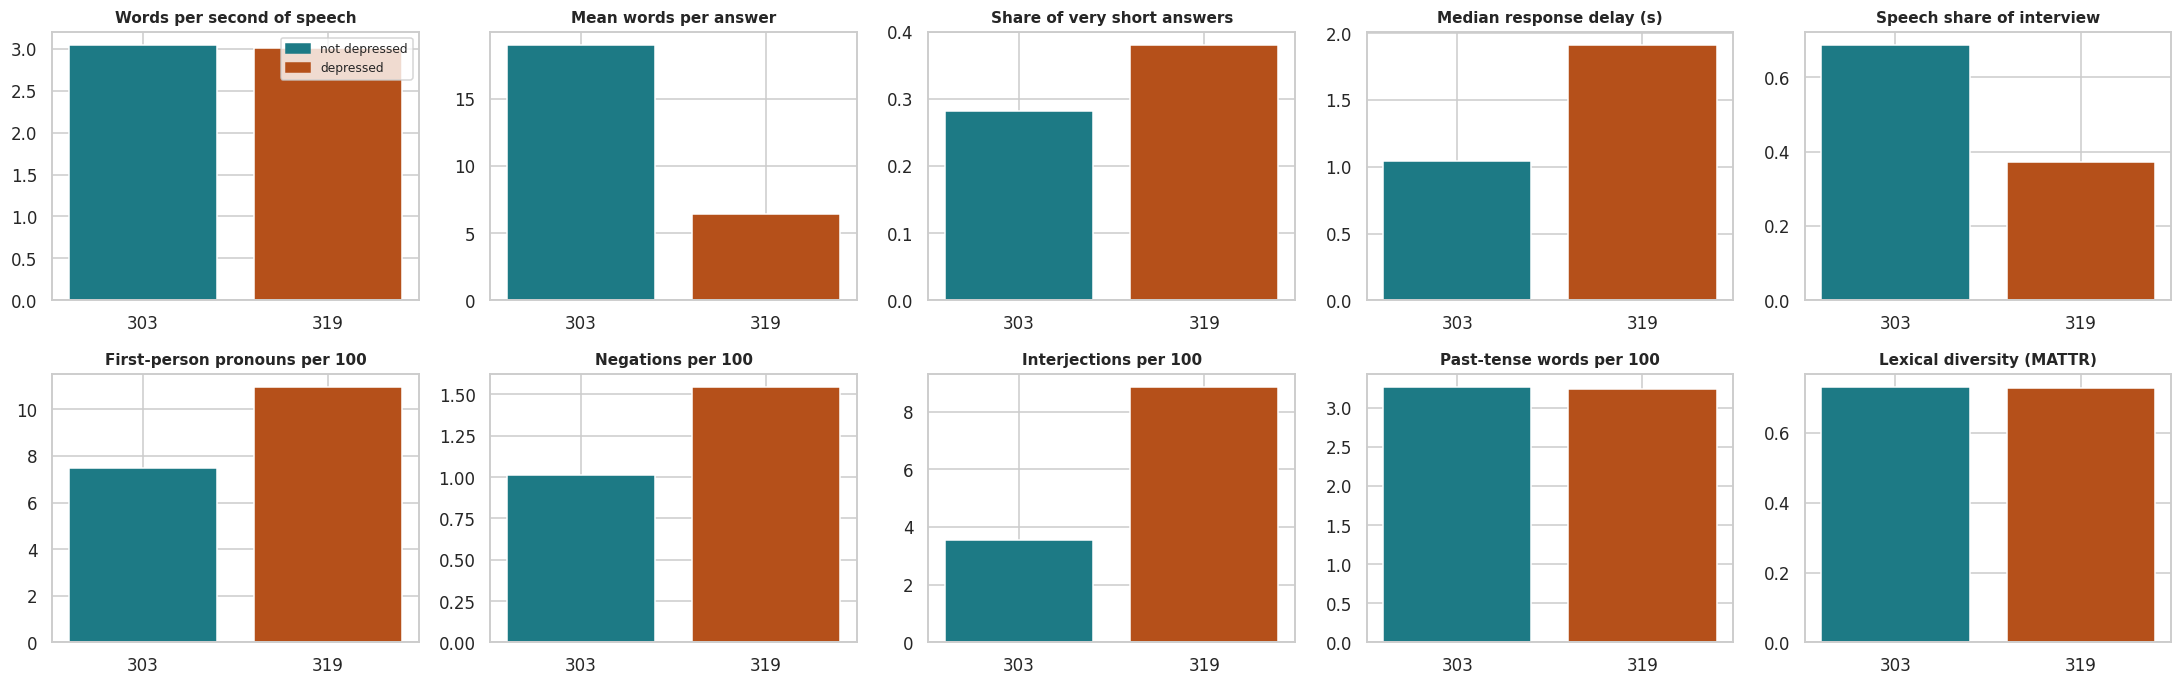

In [12]:
# BEHAVIOUR AND LANGUAGE-STRUCTURE FEATURES
require("DATA")
import spacy

MATTR_WINDOW = 50
MATTR_STRIDE = 5

try:
    nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])


def mattr(tokens, window=MATTR_WINDOW, stride=MATTR_STRIDE):
    if len(tokens) <= window:
        return len(set(tokens)) / max(len(tokens), 1)
    return float(np.mean([len(set(tokens[i:i + window])) / window for i in range(0, len(tokens) - window + 1, stride)]))


def grammar_counts(texts):
    tokens, first_person, negation, interjection, past = [], 0, 0, 0, 0
    for doc in nlp.pipe(texts, batch_size=64):
        for t in doc:
            if t.is_punct or t.is_space:
                continue
            tokens.append(t.text)
            first_person += int(t.pos_ == "PRON" and "1" in t.morph.get("Person"))
            negation += int(t.dep_ == "neg")
            interjection += int(t.pos_ == "INTJ")
            past += int("Past" in t.morph.get("Tense"))
    return tokens, first_person, negation, interjection, past


for sid, d in DATA.items():
    turns = d["turns"]
    latency = (turns["start_time"] - turns["prev_q_stop"]).clip(lower=0)
    latency = latency[latency <= LATENCY_MAX_SEC]
    speak = turns["duration"].sum()
    tokens, fp, neg, intj, past = grammar_counts(turns["clean"].tolist())
    n = max(len(tokens), 1)
    FEATURES[sid].update({
        "beh_words_per_second": turns["n_words"].sum() / max(speak, 1e-6),
        "beh_mean_turn_words": turns["n_words"].mean(),
        "beh_short_answer_share": (turns["n_words"] <= SHORT_TURN_WORDS).mean(),
        "beh_median_response_delay_sec": latency.median(),
        "beh_speech_share_of_interview": speak / (d["transcript"]["stop_time"].max() - d["transcript"]["start_time"].min()),
        "beh_first_person_per_100": 100 * fp / n,
        "beh_negation_per_100": 100 * neg / n,
        "beh_interjection_per_100": 100 * intj / n,
        "beh_past_tense_per_100": 100 * past / n,
        "beh_lexical_diversity": mattr([w.lower() for w in tokens]),
    })

BEH_COLS = ["beh_words_per_second", "beh_mean_turn_words", "beh_short_answer_share", "beh_median_response_delay_sec",
            "beh_speech_share_of_interview", "beh_first_person_per_100", "beh_negation_per_100",
            "beh_interjection_per_100", "beh_past_tense_per_100", "beh_lexical_diversity"]
display(feature_table()[["label"] + BEH_COLS].round(3).T)


@figure("01_behaviour")
def _fig_behaviour():
    grouped_bars(feature_table(), BEH_COLS, ncols=5, titles={
        "beh_words_per_second": "Words per second of speech", "beh_mean_turn_words": "Mean words per answer",
        "beh_short_answer_share": "Share of very short answers", "beh_median_response_delay_sec": "Median response delay (s)",
        "beh_speech_share_of_interview": "Speech share of interview", "beh_first_person_per_100": "First-person pronouns per 100",
        "beh_negation_per_100": "Negations per 100", "beh_interjection_per_100": "Interjections per 100",
        "beh_past_tense_per_100": "Past-tense words per 100", "beh_lexical_diversity": "Lexical diversity (MATTR)"})


FIG_FUNCS["01_behaviour"]()

## 3.2 Key interview questions and the answers given
In DAIC-WOZ the signal is often a short answer to a specific question. A bare "yes" only makes sense next to Ellie's question, so this table keeps both.

In [19]:
# QUESTION AND ANSWER PAIRS, MATCHED TO PHQ-8 ITEMS BY A LANGUAGE MODEL
require("DATA", "PHQ8_ITEMS")
import torch
from transformers import pipeline

QUESTION_MIN_WORDS = 4
QA_PER_ITEM = 2
zs_q = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=0 if torch.cuda.is_available() else -1)
labels = list(PHQ8_ITEMS.values()) + [OTHER_LABEL]

frames = []
for sid, d in DATA.items():
    t = d["turns"].dropna(subset=["prev_question"])
    qa = (t.groupby(["prev_q_stop", "prev_question"])
           .agg(answer=("clean", " ".join), answer_words=("n_words", "sum")).reset_index())
    qa = qa[qa["prev_question"].str.split().str.len() >= QUESTION_MIN_WORDS].reset_index(drop=True)
    res = zs_q(qa["prev_question"].tolist(), candidate_labels=labels,
               hypothesis_template="This question asks about {}.", batch_size=8)
    qa["topic"] = [ITEM_BY_TEXT[r["labels"][0]] for r in res]
    qa["match"] = [r["scores"][0] for r in res]
    qa.insert(0, "session", sid)
    frames.append(qa)
QA = pd.concat(frames, ignore_index=True)

pd.set_option("display.max_colwidth", 150)
for sid in SESSIONS:
    sub = QA[(QA["session"] == sid) & (QA["topic"] != "other")]
    best = sub.sort_values("match", ascending=False).groupby("topic").head(QA_PER_ITEM).sort_values(["topic", "match"], ascending=[True, False])
    print(f"\n{sess_label(sid)}: best PHQ-8 matches ({len(sub)} of {int((QA['session'] == sid).sum())} questions matched an item)")
    display(best[["topic", "match", "prev_question", "answer"]].round(2).reset_index(drop=True))

repeated = QA.groupby("prev_question").agg(sessions=("session", "nunique"), times=("session", "size"), topic=("topic", "first"))
repeated = repeated[repeated["sessions"] > 1].sort_values("times", ascending=False)
print("\nQuestions asked in more than one session (the scripted core of the interview):")
display(repeated.head(15).reset_index())

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

... (4 outputs left out)


319 (depressed): best PHQ-8 matches (27 of 48 questions matched an item)


,topic,match,prev_question,answer
0,fatigue,0.49,what are you like when you don't sleep well,irritable cranky
1,fatigue,0.27,what were your symptoms,well you know i was always tired and not excited about things anymore and kinda lethargic you know laying around and just not feeling myself
2,low interest,0.72,what are some things you don't really like about l_a,so spread out so hard to get places
3,low interest,0.70,what do you do when you're annoyed,mm um i try to remove myself from that situation that's annoying me
4,low mood,0.53,what got you to seek help,um recognizing that there were some things in me that that were wrong
5,low mood,0.46,have you been diagnosed with depression,yes
6,self-blame,0.65,is there anything you regret,no i have many regrets too many to name and number but um you know it's you know you have the the benefit of hindsight and yeah i have a lot of re...
7,self-blame,0.40,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself



Questions asked in more than one session (the scripted core of the interview):


,prev_question,sessions,times,topic
0,what's the hardest thing about being a parent,2,3,self-blame
1,have you been diagnosed with depression,2,2,low mood
2,have you ever served in the military,2,2,self-blame
3,how are you at controlling your temper,2,2,self-blame
4,do you find it easy to be a parent,2,2,low interest
5,how did you feel in that moment,2,2,other
6,tell me more about that,2,2,other
7,what advice would you give yourself ten or twenty years ago,2,2,other
8,thanks for sharing your thoughts with me,2,2,low mood
9,what are some things you really like about l_a,2,2,other


## 3.3 Text chunks for the classifiers
Participant speech only, cut into fixed-length chunks. The same cleaning is applied to your training text, so the models see the same kind of input.

In [14]:
# PARTICIPANT TEXT CHUNKS
require("DATA")
rows = []
for sid, d in DATA.items():
    words, times = [], []
    for _, r in d["turns"].iterrows():
        for w in normalise(r["clean"]).split():
            words.append(w)
            times.append(r["start_time"])
    k = 0
    for s in range(0, len(words), CHUNK_WORDS):
        piece = words[s:s + CHUNK_WORDS]
        if len(piece) < MIN_CHUNK_WORDS:
            continue
        rows.append({"session": sid, "chunk": k, "start_sec": times[s], "text": " ".join(piece)})
        k += 1
CHUNKS = pd.DataFrame(rows)
display(CHUNKS.groupby("session").agg(chunks=("chunk", "size"), first_sec=("start_sec", "min"), last_sec=("start_sec", "max")).round(0))

,chunks,first_sec,last_sec
session,,,
303,33,51.0,931.0
319,12,71.0,611.0


# 4. Text analysis
Tone and clinical content are different things. This block measures both and keeps them apart.

## 4.1 Tone of each answer
One RoBERTa sentiment score per answer, nothing truncated, stop words kept. The shares are counted on the model's own label, so neutral is never counted as positive.

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

... (5 outputs left out)

,start_time,tone,prev_question,clean
69,723.64,-0.85,how hard is that,it's very frustrating because it's like i'm talking to a wall and she's not hearing me and i'm like it seem like it's taking forever for her to ch...
77,816.81,-0.83,what are you like when you don't sleep well,what am i like irritated tired um lazy
12,173.24,-0.77,do you consider yourself an introvert,what do you mean i'm sorry



319 (depressed): most negative answers


,start_time,tone,prev_question,clean
97,586.40,-0.89,is there anything you regret,no i have many regrets too many to name and number
23,193.28,-0.82,what do you do when you're annoyed,um i try to remove myself from that situation that's annoying me
59,384.57,-0.81,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself


,label,text_tone_mean,text_tone_word_weighted,text_negative_turn_share,text_neutral_turn_share,text_positive_turn_share,text_most_negative_tone
session,,,,,,,
303,0,0.131,0.194,0.162,0.541,0.297,-0.855
319,1,0.045,0.033,0.262,0.492,0.246,-0.894


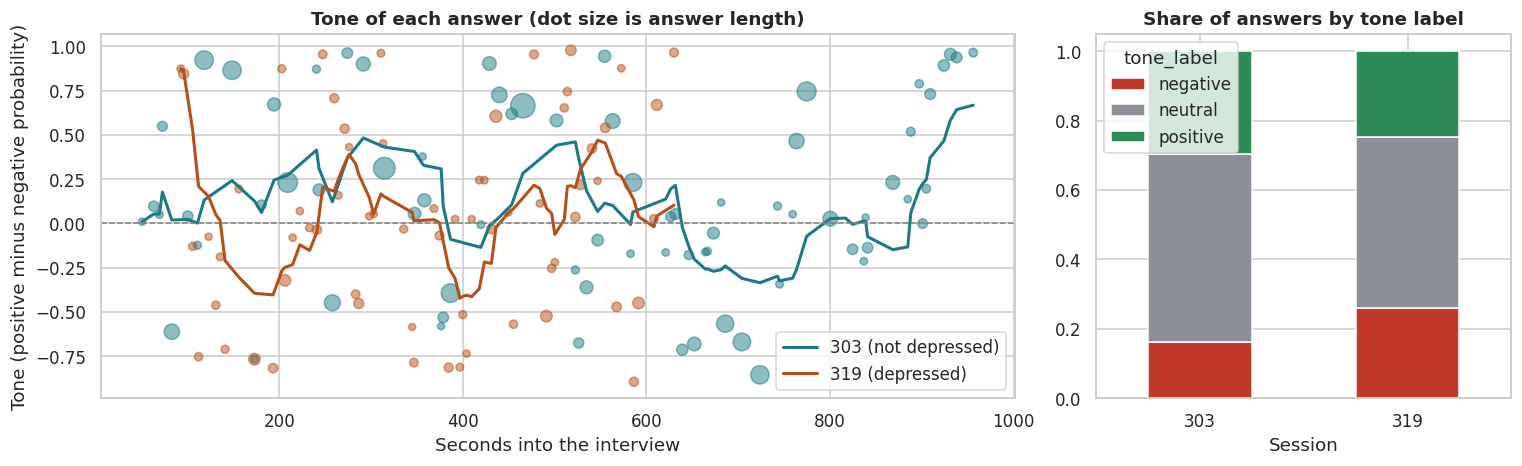

In [20]:
# TONE PER ANSWER
require("DATA")
import torch
from transformers import pipeline

HF_DEVICE = 0 if torch.cuda.is_available() else -1
tone_pipe = pipeline("text-classification", model="cardiffnlp/twitter-roberta-base-sentiment-latest", top_k=None, device=HF_DEVICE)

TURN_TONE = {}
for sid, d in DATA.items():
    t = d["turns"][d["turns"]["n_words"] >= TONE_MIN_WORDS].copy()
    outs = tone_pipe(t["clean"].tolist(), batch_size=16, truncation=True, max_length=256)
    probs = pd.DataFrame([{o["label"].lower(): o["score"] for o in out} for out in outs], index=t.index)
    t = t.join(probs[["negative", "neutral", "positive"]])
    t["tone"] = t["positive"] - t["negative"]
    t["tone_label"] = probs[["negative", "neutral", "positive"]].idxmax(axis=1)
    TURN_TONE[sid] = t
    FEATURES[sid].update({
        "text_tone_mean": t["tone"].mean(),
        "text_tone_word_weighted": np.average(t["tone"], weights=t["n_words"]),
        "text_negative_turn_share": (t["tone_label"] == "negative").mean(),
        "text_neutral_turn_share": (t["tone_label"] == "neutral").mean(),
        "text_positive_turn_share": (t["tone_label"] == "positive").mean(),
        "text_most_negative_tone": t["tone"].min(),
    })
    print(f"\n{sess_label(sid)}: most negative answers")
    display(t.nsmallest(3, "tone")[["start_time", "tone", "prev_question", "clean"]].round(2))

TEXT_COLS = ["text_tone_mean", "text_tone_word_weighted", "text_negative_turn_share", "text_neutral_turn_share",
             "text_positive_turn_share", "text_most_negative_tone"]
display(feature_table()[["label"] + TEXT_COLS].round(3))


@figure("02_tone")
def _fig_tone():
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2.2, 1]})
    for sid, t in TURN_TONE.items():
        c = LABEL_COLORS[SESSIONS[sid]]
        axes[0].scatter(t["start_time"], t["tone"], s=14 + 2 * t["n_words"], alpha=0.5, color=c)
        axes[0].plot(t["start_time"], t["tone"].rolling(7, min_periods=1).mean(), color=c, lw=2, label=sess_label(sid))
    axes[0].axhline(0, color="grey", lw=1, ls="--")
    axes[0].set_xlabel("Seconds into the interview")
    axes[0].set_ylabel("Tone (positive minus negative probability)")
    axes[0].set_title("Tone of each answer (dot size is answer length)")
    axes[0].legend()
    share = pd.DataFrame({sid: t["tone_label"].value_counts(normalize=True) for sid, t in TURN_TONE.items()}).T
    share = share.reindex(columns=["negative", "neutral", "positive"]).fillna(0)
    share.index = [str(s) for s in share.index]
    share.plot(kind="bar", stacked=True, ax=axes[1], color=["#C0392B", "#8A8F98", "#2E8B57"])
    axes[1].set_title("Share of answers by tone label")
    axes[1].set_xlabel("Session")
    axes[1].tick_params(axis="x", rotation=0)


FIG_FUNCS["02_tone"]()

## 4.2 Wording cues
First-person words, negations and absolutist words were already counted in 3.1. This cell lists the answers that contain the strongest PHQ-8 cue phrases, so the evidence can be read directly.


303 (not depressed): terms used more here than in the other sessions


,term,z,count_here,count_in_others
0,you,2.25,117.0,23.0
1,they,1.93,17.0,0.0
2,like,1.80,33.0,4.0
3,kinda like,1.40,9.0,0.0
4,with,1.35,13.0,1.0
5,so i,1.32,8.0,0.0
6,feel,1.32,8.0,0.0
7,probably,1.32,8.0,0.0
8,what,1.32,8.0,0.0
9,go,1.32,8.0,0.0



319 (depressed): terms used more here than in the other sessions


,term,z,count_here,count_in_others
0,mm,2.94,9.0,0.0
1,about,2.62,8.0,4.0
2,that's,2.28,10.0,9.0
3,well,2.23,11.0,11.0
4,um,2.21,21.0,30.0
5,hmm,2.19,5.0,0.0
6,say,2.19,5.0,2.0
7,'em,2.08,4.0,1.0
8,i don't,2.08,4.0,1.0
9,um i,2.05,6.0,4.0


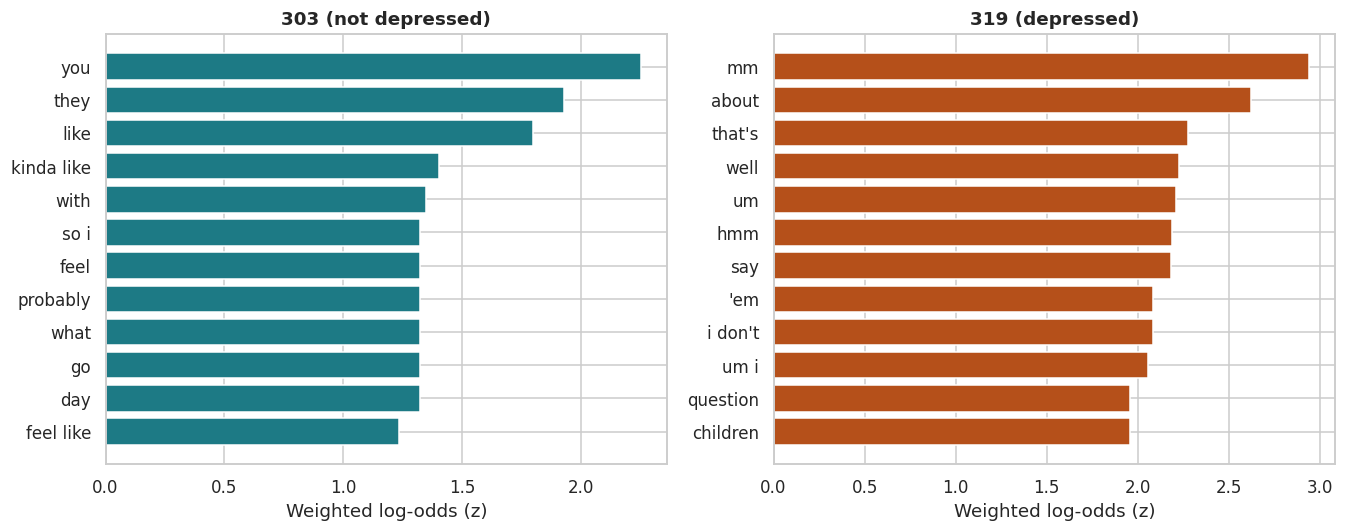

In [17]:
# DISTINCTIVE WORDS AND PHRASES PER SESSION (WEIGHTED LOG-ODDS)
require("DATA")
from sklearn.feature_extraction.text import CountVectorizer

KEYNESS_PRIOR_MASS = 500.0
KEYNESS_MIN_COUNT = 3
KEYNESS_TOP = 12

if len(DATA) < 2:
    raise RuntimeError("Distinctive wording needs at least two sessions to compare.")

sids = list(DATA)
docs = [" ".join(normalise(x) for x in DATA[s]["turns"]["clean"]) for s in sids]
cv = CountVectorizer(ngram_range=(1, 2), token_pattern=r"[a-z']+")
X = cv.fit_transform(docs).toarray().astype(float)
terms = np.array(cv.get_feature_names_out())
prior = X.sum(axis=0)
prior = prior / prior.sum() * KEYNESS_PRIOR_MASS
a0 = prior.sum()

KEYNESS = {}
for i, sid in enumerate(sids):
    a = X[i]
    b = X.sum(axis=0) - a
    la = np.log((a + prior) / (a.sum() + a0 - a - prior))
    lb = np.log((b + prior) / (b.sum() + a0 - b - prior))
    z = (la - lb) / np.sqrt(1 / (a + prior) + 1 / (b + prior))
    table = pd.DataFrame({"term": terms, "z": z, "count_here": a, "count_in_others": b})
    table = table[table["count_here"] >= KEYNESS_MIN_COUNT].sort_values("z", ascending=False)
    KEYNESS[sid] = table.head(KEYNESS_TOP).reset_index(drop=True)
    print(f"\n{sess_label(sid)}: terms used more here than in the other sessions")
    display(KEYNESS[sid].round(2))


@figure("03_keyness")
def _fig_keyness():
    fig, axes = plt.subplots(1, len(KEYNESS), figsize=(6.2 * len(KEYNESS), 5), squeeze=False)
    for ax, (sid, tbl) in zip(axes[0], KEYNESS.items()):
        tbl = tbl.iloc[::-1]
        ax.barh(tbl["term"], tbl["z"], color=LABEL_COLORS[SESSIONS[sid]])
        ax.set_title(sess_label(sid))
        ax.set_xlabel("Weighted log-odds (z)")


FIG_FUNCS["03_keyness"]()

## 4.3 PHQ-8 symptom evidence (experimental)
Zero-shot scores for the eight PHQ-8 symptoms on each answer. The scores are not calibrated, so only compare the same symptom between sessions, never one symptom against another.

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

,303,319
low interest,0.149,0.239
low mood,0.438,0.412
sleep problems,0.213,0.165
fatigue,0.505,0.496
appetite change,0.065,0.056
self-blame,0.479,0.497
poor concentration,0.371,0.329
slowed or restless,0.546,0.633



303 (not depressed): highest-scoring answers per symptom


,symptom,score,time,question,answer
0,low interest,1.00,817,what are you like when you don't sleep well,what am i like irritated tired um lazy
1,low interest,1.00,547,what advice would you give yourself ten or twenty years ago,rather i probably would've stayed in school and probably have a part time job or something just i just feel like um
2,low mood,1.00,547,what advice would you give yourself ten or twenty years ago,rather i probably would've stayed in school and probably have a part time job or something just i just feel like um
3,low mood,1.00,825,what are you like when you don't sleep well,feel like i wanna lay down probably go to sleep get the rest that i need but
4,sleep problems,0.99,817,what are you like when you don't sleep well,what am i like irritated tired um lazy
5,sleep problems,0.99,825,what are you like when you don't sleep well,feel like i wanna lay down probably go to sleep get the rest that i need but
6,fatigue,1.00,825,what are you like when you don't sleep well,feel like i wanna lay down probably go to sleep get the rest that i need but
7,fatigue,1.00,817,what are you like when you don't sleep well,what am i like irritated tired um lazy
8,appetite change,0.37,825,what are you like when you don't sleep well,feel like i wanna lay down probably go to sleep get the rest that i need but
9,appetite change,0.34,704,mhm,and now she's she regretting it you know 'cause she's like my mom told me this you know mom i'm doing the opposite so i guess she gotta bump her h...



319 (depressed): highest-scoring answers per symptom


,symptom,score,time,question,answer
0,low interest,0.99,385,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself
1,low interest,0.97,347,why,i don't have the funds to do that anymore
2,low mood,1.00,385,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself
3,low mood,0.98,491,could you say a little more about that,well there's been a lot going on in my life you know i just lost my parent my dad my last parent
4,sleep problems,0.76,385,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself
5,sleep problems,0.75,283,what's the hardest thing about being a parent,you worry all the time you worry for 'em
6,fatigue,0.99,112,what are some things you don't really like about l_a,so spread out so hard to get places
7,fatigue,0.99,385,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself
8,appetite change,0.33,431,can you tell me about that,well it's you know it's you know i see a psychologist and um
9,appetite change,0.20,385,did you think you had a problem before you found out,i knew that there was something wrong 'cause i wasn't myself


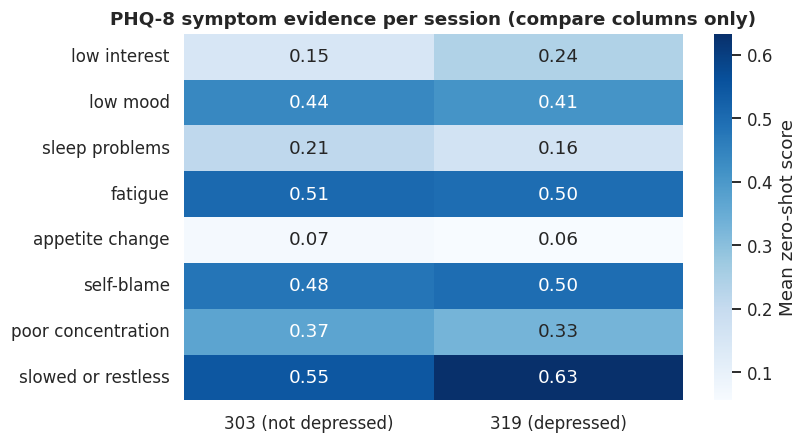

In [21]:
# ZERO-SHOT PHQ-8 SYMPTOMS PER ANSWER, WITH THE EVIDENCE
require("DATA", "PHQ8_ITEMS")
if not RUN_SYMPTOMS:
    print("RUN_SYMPTOMS is off.")
else:
    import torch
    from transformers import pipeline
    EVIDENCE_TOP = 2
    zs = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=0 if torch.cuda.is_available() else -1)
    item_texts = list(PHQ8_ITEMS.values())
    SYMPTOM_TURNS, SYMPTOM_MEANS = {}, {}
    for sid, d in DATA.items():
        t = d["turns"][d["turns"]["n_words"] >= SYMPTOM_MIN_WORDS].reset_index(drop=True)
        res = zs(t["clean"].tolist(), candidate_labels=item_texts, multi_label=True,
                 hypothesis_template="The speaker talks about {}.", batch_size=4)
        scores = pd.DataFrame([{ITEM_BY_TEXT[l]: s for l, s in zip(r["labels"], r["scores"])} for r in res])[list(PHQ8_ITEMS)]
        SYMPTOM_TURNS[sid] = pd.concat([t[["start_time", "prev_question", "clean"]], scores], axis=1)
        SYMPTOM_MEANS[sid] = scores.mean()
        for name in PHQ8_ITEMS:
            FEATURES[sid][f"text_symptom_{name.replace(' ', '_').replace('-', '_')}"] = scores[name].mean()
    SYMPTOM_TABLE = pd.DataFrame(SYMPTOM_MEANS)
    display(SYMPTOM_TABLE.round(3))

    for sid, tt in SYMPTOM_TURNS.items():
        rows = []
        for name in PHQ8_ITEMS:
            for _, r in tt.nlargest(EVIDENCE_TOP, name).iterrows():
                rows.append({"symptom": name, "score": r[name], "time": round(r["start_time"]),
                             "question": str(r["prev_question"])[:70], "answer": r["clean"][:150]})
        print(f"\n{sess_label(sid)}: highest-scoring answers per symptom")
        display(pd.DataFrame(rows).round(2))

    @figure("03_symptoms")
    def _fig_symptoms():
        T = SYMPTOM_TABLE.copy()
        T.columns = [sess_label(c) for c in T.columns]
        fig, ax = plt.subplots(figsize=(1.8 * len(T.columns) + 4, 4.2))
        sns.heatmap(T, annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar_kws={"label": "Mean zero-shot score"})
        ax.set_title("PHQ-8 symptom evidence per session (compare columns only)")

    FIG_FUNCS["03_symptoms"]()

# 5. Voice
Column names follow the AVEC documentation: F0, VUV, NAQ, QOQ, H1H2, PSP, MDQ, peakSlope, Rd, Rd_conf, then MCEP, HMPDM and HMPDD. Only participant speech is used. Frames where the file is scrubbed (all zeros) are treated as missing.

## 5.1 Voice descriptors

session,303,319
label,0.000,1.000
voice_voiced_share,0.658,0.641
voice_f0_mean_hz,192.968,103.658
voice_f0_std_hz,36.175,24.400
voice_f0_range_hz,104.500,74.500
voice_NAQ_median,0.124,0.094
voice_QOQ_median,0.471,0.286
voice_H1H2_median,6.661,-0.659
voice_PSP_median,0.234,0.160
voice_MDQ_median,0.111,0.119


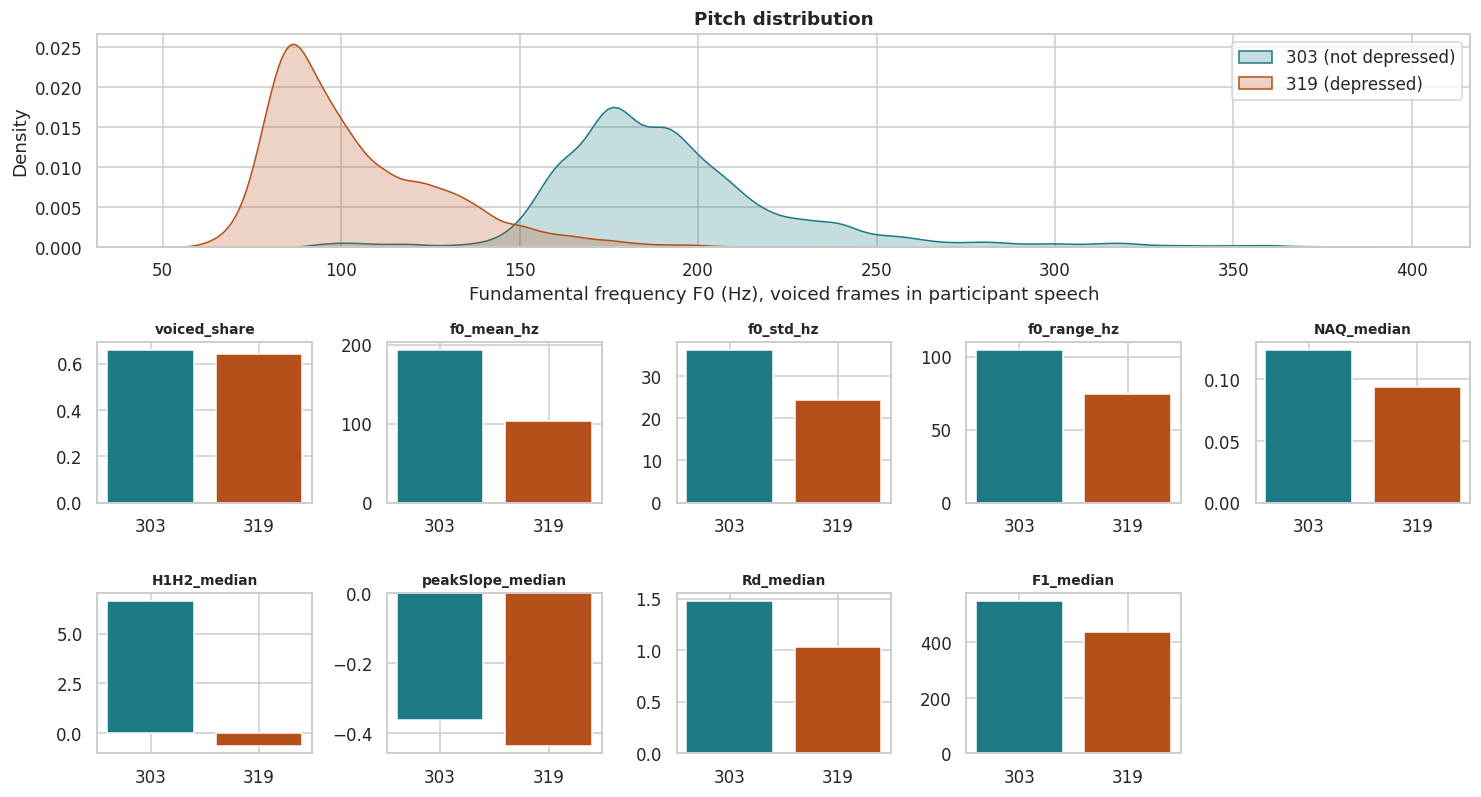

In [22]:
# COVAREP AND FORMANT DESCRIPTORS DURING PARTICIPANT SPEECH
require("DATA")
COV_NAMES = ["F0", "VUV", "NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd", "Rd_conf"]
VOICE_KEYS = ["NAQ", "QOQ", "H1H2", "PSP", "MDQ", "peakSlope", "Rd"]
VOICE = {}
for sid, d in DATA.items():
    cov = pd.read_csv(path_of(sid, "covarep"), header=None, usecols=range(len(COV_NAMES)))
    cov.columns = COV_NAMES
    fmt = pd.read_csv(path_of(sid, "formant"), header=None, names=["F1", "F2", "F3", "F4", "F5"])
    n = min(len(cov), len(fmt))
    v = pd.concat([cov.iloc[:n].reset_index(drop=True), fmt.iloc[:n].reset_index(drop=True)], axis=1)
    v["time"] = np.arange(n) * 0.01
    v = v[in_turns(v["time"], d["turns"])]
    speech_frames = len(v)
    v = v[(v["VUV"] == 1) & (v["F0"] >= F0_MIN) & (v["F0"] <= F0_MAX)].copy()
    for c in VOICE_KEYS + ["F1", "F2", "F3"]:
        v.loc[v[c] == 0, c] = np.nan
    VOICE[sid] = v
    FEATURES[sid].update({
        "voice_voiced_share": len(v) / max(speech_frames, 1),
        "voice_f0_mean_hz": v["F0"].mean(),
        "voice_f0_std_hz": v["F0"].std(),
        "voice_f0_range_hz": v["F0"].quantile(0.95) - v["F0"].quantile(0.05),
        **{f"voice_{c}_median": v[c].median() for c in VOICE_KEYS},
        **{f"voice_{c}_median": v[c].median() for c in ["F1", "F2", "F3"]},
    })

VOICE_COLS = ["voice_voiced_share", "voice_f0_mean_hz", "voice_f0_std_hz", "voice_f0_range_hz", "voice_NAQ_median",
              "voice_H1H2_median", "voice_peakSlope_median", "voice_Rd_median", "voice_F1_median"]
display(feature_table()[["label"] + [c for c in feature_table().columns if c.startswith("voice_")]].round(3).T)


@figure("04_voice")
def _fig_voice():
    fig = plt.figure(figsize=(14, 7.2))
    gs = fig.add_gridspec(2, 1, height_ratios=[1, 1.5])
    ax = fig.add_subplot(gs[0])
    for sid, v in VOICE.items():
        sns.kdeplot(v["F0"], ax=ax, color=LABEL_COLORS[SESSIONS[sid]], fill=True, alpha=0.25, label=sess_label(sid), common_norm=False)
    ax.set_xlabel("Fundamental frequency F0 (Hz), voiced frames in participant speech")
    ax.set_title("Pitch distribution")
    ax.legend()
    t = feature_table()
    cols = [c for c in VOICE_COLS if c in t.columns]
    sub = fig.add_subfigure(gs[1])
    axes = sub.subplots(2, 5)
    axes = axes.ravel()
    for a, col in zip(axes, cols):
        a.bar([str(s) for s in t.index], t[col].astype(float), color=[LABEL_COLORS[SESSIONS[s]] for s in t.index])
        a.set_title(col.replace("voice_", ""), fontsize=9)
    for a in axes[len(cols):]:
        a.axis("off")


FIG_FUNCS["04_voice"]()

## 5.2 Speech emotion (optional, slow)
The wav2vec2 model was trained on acted four-class speech. Treat its labels as a description of delivery, not as depression evidence. Turn off with `RUN_SPEECH_EMOTION = False` in Section 1.

In [23]:
# SPEECH EMOTION ON PARTICIPANT TURNS
require("DATA")
if not RUN_SPEECH_EMOTION:
    print("RUN_SPEECH_EMOTION is off.")
else:
    import torch
    from scipy.io import wavfile
    from transformers import pipeline
    emo = pipeline("audio-classification", model="superb/wav2vec2-base-superb-er", top_k=None, device=0 if torch.cuda.is_available() else -1)
    SEGMENT_SEC = 12.0
    EMOTION = {}
    for sid, d in DATA.items():
        sr, wav = wavfile.read(path_of(sid, "audio"))
        wav = wav.astype(np.float32)
        wav = wav.mean(axis=1) if wav.ndim > 1 else wav
        wav = wav / max(np.abs(wav).max(), 1.0)
        if sr != 16000:
            print(f"WARNING: sampling rate is {sr}, the model expects 16000.")
        totals, weight = Counter(), 0.0
        for _, r in d["turns"].iterrows():
            a, b = int(r["start_time"] * sr), int(r["stop_time"] * sr)
            for s in range(a, b, int(SEGMENT_SEC * sr)):
                seg = wav[s:min(s + int(SEGMENT_SEC * sr), b)]
                if len(seg) < sr or np.abs(seg).max() < 1e-4:
                    continue
                out = emo({"raw": seg, "sampling_rate": sr})
                w = len(seg) / sr
                for o in out:
                    totals[o["label"]] += o["score"] * w
                weight += w
        EMOTION[sid] = {k: v / max(weight, 1e-6) for k, v in totals.items()}
        for k, v in EMOTION[sid].items():
            FEATURES[sid][f"voice_emotion_{k}"] = v
    display(pd.DataFrame(EMOTION).round(3))

config.json:   0%|          | 0.00/2.15k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/216 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

,303,319
neu,0.261,0.334
hap,0.522,0.611
ang,0.174,0.000
sad,0.042,0.055


# 6. Face
Action units from the CLNF tracker. Frames count only when tracking succeeded with confidence above the threshold and the participant was speaking. AUs that mostly move with speech (AU10, 14, 17, 20, 25, 26) are left out.

session,303,319
label,0.000,1.000
face_AU01_r_mean,0.765,0.462
face_AU02_r_mean,0.287,0.222
face_AU04_r_mean,0.886,0.442
face_AU05_r_mean,0.289,0.258
face_AU06_r_mean,0.106,0.541
face_AU09_r_mean,0.430,0.484
face_AU12_r_mean,0.289,0.303
face_AU15_r_mean,0.172,0.143
face_smile_share,0.088,0.117


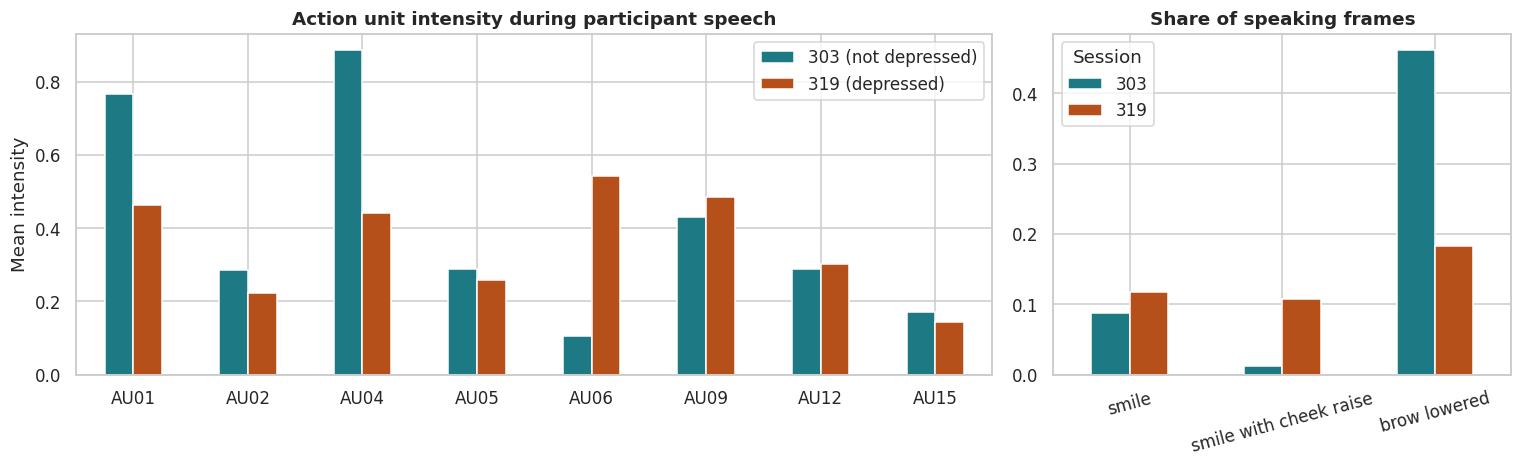

In [24]:
# ACTION UNITS DURING PARTICIPANT SPEECH
require("DATA")


def read_clnf(path):
    df = pd.read_csv(path, skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    return df


FACE = {}
for sid, d in DATA.items():
    au = read_clnf(path_of(sid, "aus"))
    speaking = in_turns(au["timestamp"], d["turns"])
    ok = (au["success"] == 1) & (au["confidence"] >= FACE_CONF_MIN) & speaking
    f = au.loc[ok, ["timestamp"] + AU_KEEP].reset_index(drop=True)
    FACE[sid] = f
    FEATURES[sid].update({f"face_{c}_mean": f[c].mean() for c in AU_KEEP})
    FEATURES[sid].update({
        "face_smile_share": (f["AU12_r"] >= AU_ON).mean(),
        "face_duchenne_share": ((f["AU12_r"] >= AU_ON) & (f["AU06_r"] >= AU_ON)).mean(),
        "face_brow_lowered_share": (f["AU04_r"] >= AU_ON).mean(),
        "face_valid_share_of_speech": ok.sum() / max(speaking.sum(), 1),
    })

FACE_COLS = [f"face_{c}_mean" for c in AU_KEEP] + ["face_smile_share", "face_duchenne_share", "face_brow_lowered_share", "face_valid_share_of_speech"]
display(feature_table()[["label"] + FACE_COLS].round(3).T)


@figure("05_face")
def _fig_face():
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2, 1]})
    mean_au = pd.DataFrame({sid: f[AU_KEEP].mean() for sid, f in FACE.items()})
    mean_au.index = [c.replace("_r", "") for c in mean_au.index]
    mean_au.columns = [sess_label(c) for c in mean_au.columns]
    mean_au.plot(kind="bar", ax=axes[0], color=[LABEL_COLORS[SESSIONS[s]] for s in FACE])
    axes[0].set_ylabel("Mean intensity")
    axes[0].set_title("Action unit intensity during participant speech")
    axes[0].tick_params(axis="x", rotation=0)
    t = feature_table()
    shares = t[["face_smile_share", "face_duchenne_share", "face_brow_lowered_share"]]
    shares.index = [str(s) for s in shares.index]
    shares.columns = ["smile", "smile with cheek raise", "brow lowered"]
    shares.T.plot(kind="bar", ax=axes[1], color=[LABEL_COLORS[SESSIONS[s]] for s in t.index])
    axes[1].set_title("Share of speaking frames")
    axes[1].tick_params(axis="x", rotation=15)
    axes[1].legend(title="Session")


FIG_FUNCS["05_face"]()

# 7. Gaze and head movement
Eye vectors become yaw and pitch angles in degrees. Head angles are unwrapped before differencing and speeds are computed only between consecutive frames, so tracker gaps and angle wrap-around do not create fake spikes.

session,303,319
label,0.000,1.000
gaze_yaw_std_deg,2.964,3.040
gaze_pitch_std_deg,2.159,5.169
gaze_frontal_share,0.982,0.207
gaze_speed_median_deg_s,33.579,30.381
head_speed_median_deg_s,21.082,14.460
head_speed_p90_deg_s,57.331,36.484
head_pitch_std_deg,3.562,8.677
head_yaw_std_deg,5.317,3.470


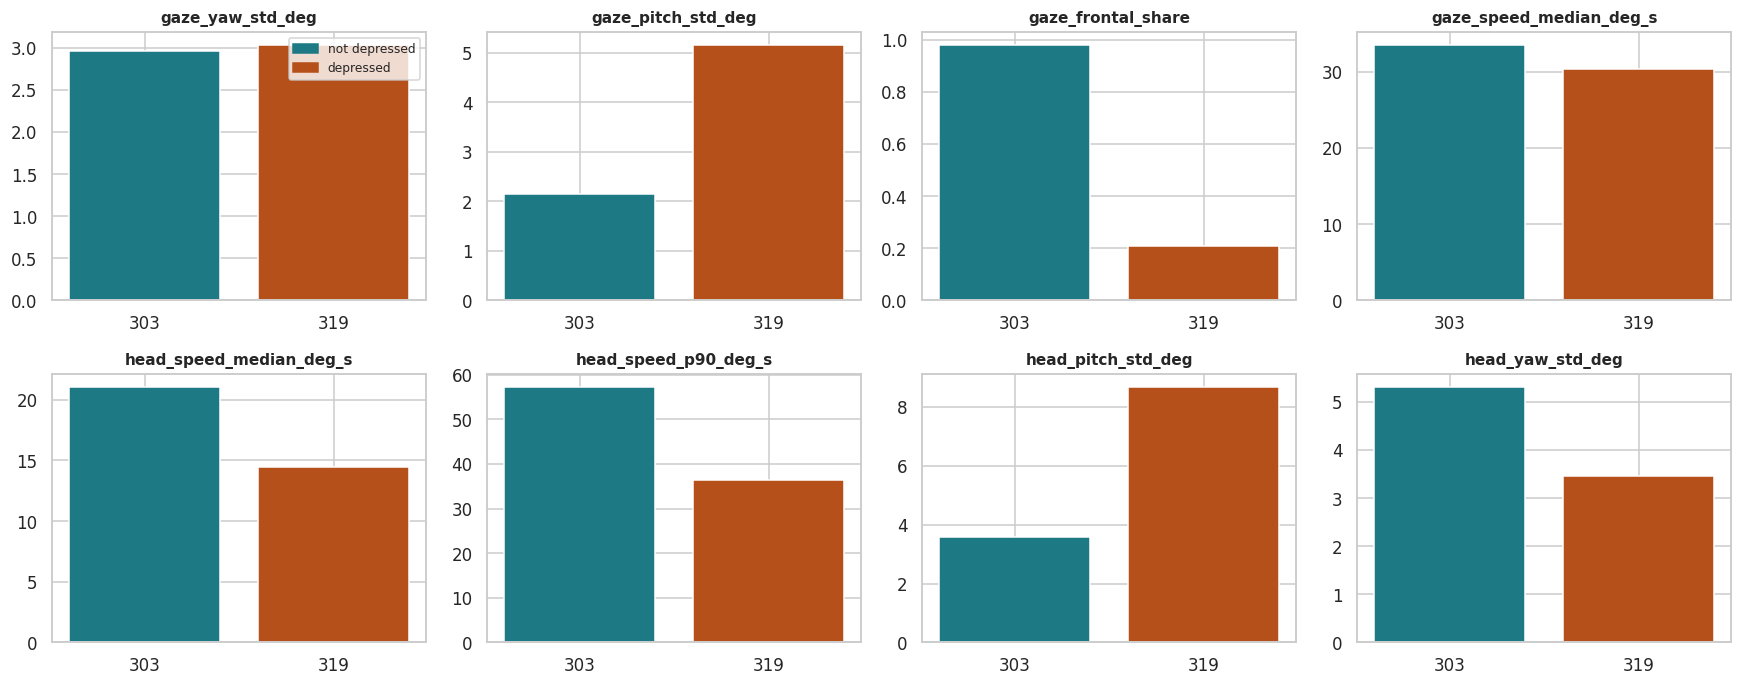

In [25]:
# GAZE AND HEAD MOTION DURING PARTICIPANT SPEECH
require("DATA")


def read_clnf(path):
    df = pd.read_csv(path, skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    return df


def speed_between_frames(time, *signals):
    dt = np.diff(time, prepend=np.nan)
    delta = np.sqrt(sum(np.diff(s, prepend=np.nan) ** 2 for s in signals))
    speed = delta / dt
    speed[~((dt > 0) & (dt <= FRAME_GAP_MAX))] = np.nan
    return speed


GAZE, HEAD = {}, {}
for sid, d in DATA.items():
    g = read_clnf(path_of(sid, "gaze"))
    g = g[(g["success"] == 1) & (g["confidence"] >= FACE_CONF_MIN)].reset_index(drop=True)
    vec = (g[["x_0", "y_0", "z_0"]].to_numpy() + g[["x_1", "y_1", "z_1"]].to_numpy()) / 2
    gz = pd.DataFrame({"time": g["timestamp"].to_numpy(),
                       "yaw": np.degrees(np.arctan2(vec[:, 0], -vec[:, 2])),
                       "pitch": np.degrees(np.arctan2(vec[:, 1], -vec[:, 2]))})
    gz["speed"] = speed_between_frames(gz["time"].to_numpy(), gz["yaw"].to_numpy(), gz["pitch"].to_numpy())
    gz = gz[in_turns(gz["time"], d["turns"])]

    p = read_clnf(path_of(sid, "pose"))
    p = p[(p["success"] == 1) & (p["confidence"] >= FACE_CONF_MIN)].reset_index(drop=True)
    ang = np.degrees(np.unwrap(p[["Rx", "Ry", "Rz"]].to_numpy(), axis=0))
    hd = pd.DataFrame({"time": p["timestamp"].to_numpy(), "pitch": ang[:, 0], "yaw": ang[:, 1], "roll": ang[:, 2]})
    hd["speed"] = speed_between_frames(hd["time"].to_numpy(), hd["pitch"].to_numpy(), hd["yaw"].to_numpy(), hd["roll"].to_numpy())
    hd = hd[in_turns(hd["time"], d["turns"])]
    GAZE[sid], HEAD[sid] = gz, hd
    FEATURES[sid].update({
        "gaze_yaw_std_deg": gz["yaw"].std(),
        "gaze_pitch_std_deg": gz["pitch"].std(),
        "gaze_frontal_share": ((gz["yaw"].abs() < FRONTAL_DEG) & (gz["pitch"].abs() < FRONTAL_DEG)).mean(),
        "gaze_speed_median_deg_s": gz["speed"].median(),
        "head_speed_median_deg_s": hd["speed"].median(),
        "head_speed_p90_deg_s": hd["speed"].quantile(0.9),
        "head_pitch_std_deg": hd["pitch"].std(),
        "head_yaw_std_deg": hd["yaw"].std(),
    })

GAZE_COLS = [c for c in feature_table().columns if c.startswith(("gaze_", "head_"))]
display(feature_table()[["label"] + GAZE_COLS].round(3).T)


@figure("06_gaze_head")
def _fig_gaze():
    t = feature_table()
    grouped_bars(t, GAZE_COLS, ncols=4)


FIG_FUNCS["06_gaze_head"]()

# 8. Fusion
Fusion here means putting the streams side by side on one timeline and in one table, in real units. No feature is standardised inside a single interview, because that removes the difference between people that you want to see. With two sessions this is description, not a statistical test.

session,303,319
label,0.000,1.000
beh_words_per_second,3.049,3.006
beh_mean_turn_words,19.029,6.400
beh_short_answer_share,0.282,0.381
beh_median_response_delay_sec,1.040,1.915
...,...,...
gaze_speed_median_deg_s,33.579,30.381
head_speed_median_deg_s,21.082,14.460
head_speed_p90_deg_s,57.331,36.484
head_pitch_std_deg,3.562,8.677


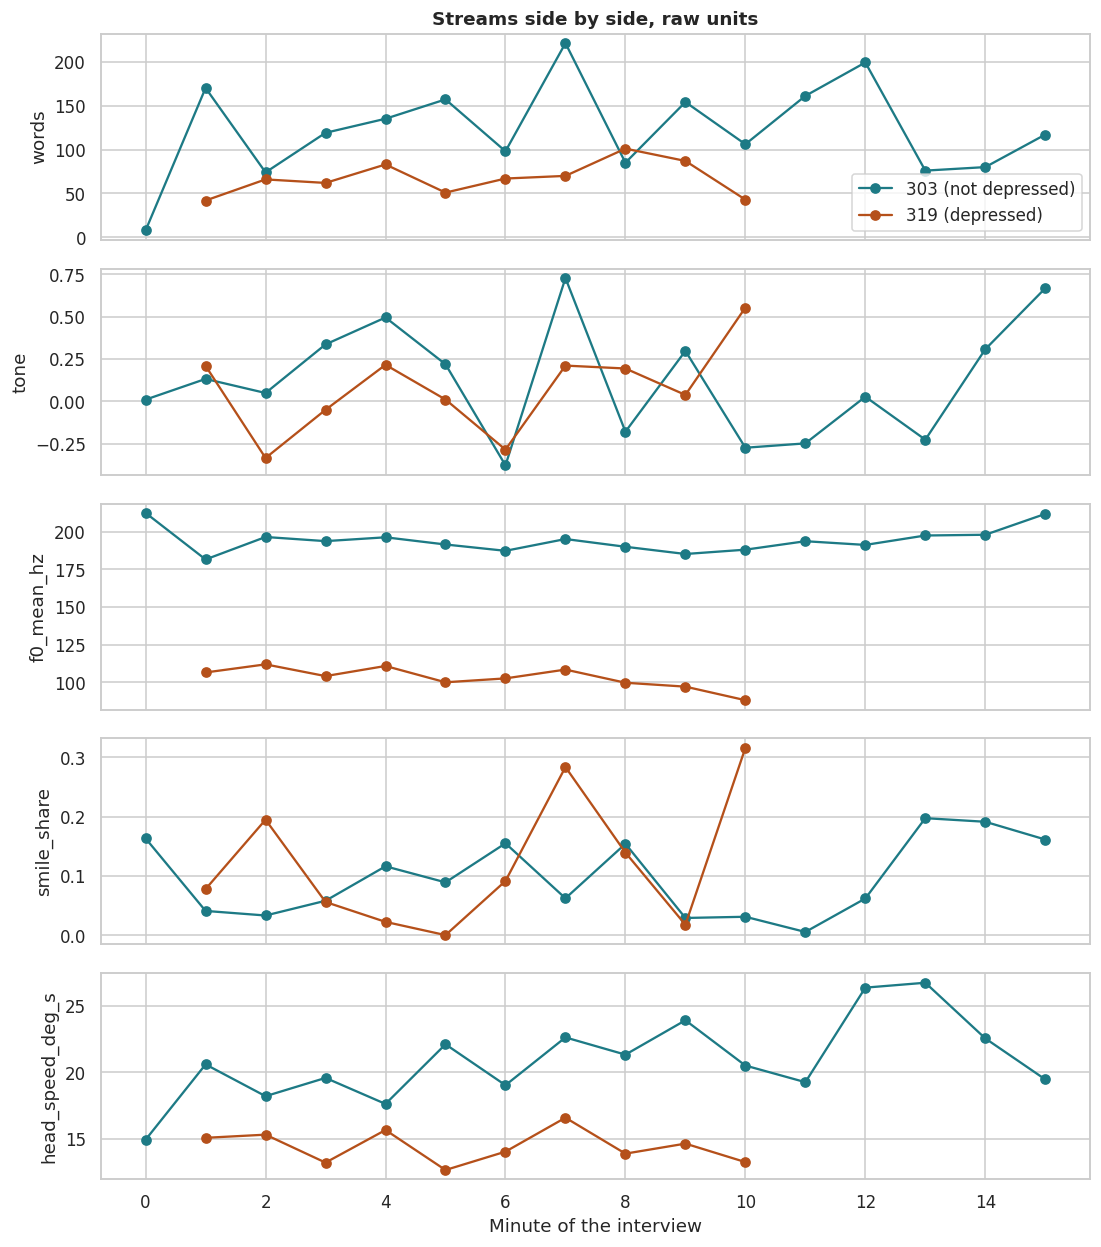

In [26]:
# PER-MINUTE TIMELINE AND ALL-SESSION FEATURE TABLE
require("DATA")
WINDOWS = {}
for sid, d in DATA.items():
    parts = {}
    parts["words"] = d["turns"].groupby((d["turns"]["start_time"] // WINDOW_SEC).astype(int))["n_words"].sum()
    if "TURN_TONE" in globals() and sid in TURN_TONE:
        t = TURN_TONE[sid]
        parts["tone"] = t.groupby((t["start_time"] // WINDOW_SEC).astype(int))["tone"].mean()
    if "VOICE" in globals() and sid in VOICE:
        v = VOICE[sid]
        parts["f0_mean_hz"] = v.groupby((v["time"] // WINDOW_SEC).astype(int))["F0"].mean()
    if "FACE" in globals() and sid in FACE:
        f = FACE[sid]
        parts["smile_share"] = (f["AU12_r"] >= AU_ON).groupby((f["timestamp"] // WINDOW_SEC).astype(int)).mean()
    if "HEAD" in globals() and sid in HEAD:
        h = HEAD[sid]
        parts["head_speed_deg_s"] = h.groupby((h["time"] // WINDOW_SEC).astype(int))["speed"].median()
    WINDOWS[sid] = pd.concat(parts, axis=1)
    WINDOWS[sid].index.name = "minute"
    # A last window that covers less than half a window is too short to compare, so it is dropped.
    end = d["transcript"]["stop_time"].max()
    last = int(end // WINDOW_SEC)
    if end - last * WINDOW_SEC < WINDOW_SEC / 2 and last in WINDOWS[sid].index:
        WINDOWS[sid] = WINDOWS[sid].drop(index=last)

ALL_FEATURES = feature_table()
display(ALL_FEATURES.round(3).T)


@figure("07_timeline")
def _fig_timeline():
    cols = [c for c in ["words", "tone", "f0_mean_hz", "smile_share", "head_speed_deg_s"] if any(c in w.columns for w in WINDOWS.values())]
    fig, axes = plt.subplots(len(cols), 1, figsize=(10, 2.3 * len(cols)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, col in zip(axes, cols):
        for sid, w in WINDOWS.items():
            if col in w.columns:
                ax.plot(w.index, w[col], marker="o", color=LABEL_COLORS[SESSIONS[sid]], label=sess_label(sid))
        ax.set_ylabel(col)
    axes[0].legend()
    axes[-1].set_xlabel("Minute of the interview")
    axes[0].set_title("Streams side by side, raw units")


FIG_FUNCS["07_timeline"]()

# 9. Train LSTM and BiLSTM on your datasets
Requires `TRAIN_SOURCES` in Section 1 and the chunks from 3.3 (used only to remove overlapping text).

## 9.1 Load, clean and split without leakage

In [33]:
# LOAD TRAINING DATA, REMOVE LEAKAGE, SPLIT
require("CHUNKS")
from sklearn.model_selection import train_test_split, GroupShuffleSplit

if len(TRAIN_SOURCES) == 0:
    raise ValueError("TRAIN_SOURCES is empty. Add at least one dataset in Section 1.")


def read_any(path):
    p = str(path).lower()
    if p.endswith(".json"):
        return pd.read_json(path)
    if p.endswith(".tsv"):
        return pd.read_csv(path, sep="\t")
    return pd.read_csv(path)

def daic_frame(src):
    """Turn unzipped DAIC-WOZ session folders into labelled text chunks. The participant id is the group."""
    labels = pd.concat([pd.read_csv(p).rename(columns={"PHQ_Binary": "PHQ8_Binary"})[["Participant_ID", "PHQ8_Binary"]]
                        for p in src["label_files"]], ignore_index=True).drop_duplicates("Participant_ID").set_index("Participant_ID")
    rows = []
    for sid in src["daic_ids"]:
        if sid in SESSIONS:
            print(f"Skipping {sid}: it is a test session.")
            continue
        file = Path(src["daic_dir"]) / f"{sid}_P" / f"{sid}_TRANSCRIPT.csv"
        if sid not in labels.index or not file.exists():
            print(f"Skipping {sid}: missing label or transcript.")
            continue
        tr = pd.read_csv(file, sep="\t")
        tr = tr[tr["speaker"] == "Participant"].sort_values("start_time")
        words = [w for v in tr["value"].fillna("").astype(str) for w in normalise(v).split()
                 if w not in ("xxx", "scrubbed_entry", "synch")]
        for s in range(0, len(words), CHUNK_WORDS):
            piece = words[s:s + CHUNK_WORDS]
            if len(piece) >= MIN_CHUNK_WORDS:
                rows.append({"text": " ".join(piece), "label": int(labels.loc[sid, "PHQ8_Binary"]), "participant": sid})
    return pd.DataFrame(rows)


frames = []
for src in TRAIN_SOURCES:
    if "daic_ids" in src:
        raw = daic_frame(src)
        print("DAIC-WOZ training sessions per class:", raw.groupby("participant")["label"].first().value_counts().to_dict())
        src = {"path": "daic_sessions", "text_col": "text", "label_col": "label", "depressed_values": [1], "group_col": "participant"}
    else:
        raw = read_any(src["path"])
    positive = {str(v) for v in src["depressed_values"]}
    name = Path(src["path"]).name
    group = (name + "::" + raw[src["group_col"]].astype(str)) if "group_col" in src else (name + "::row" + raw.index.astype(str))
    frames.append(pd.DataFrame({"text": raw[src["text_col"]].map(normalise),
                                "label": raw[src["label_col"]].astype(str).isin(positive).astype(int),
                                "source": name, "group": group.values}))
train_all = pd.concat(frames, ignore_index=True)
n_start = len(train_all)

# Rule one: short texts, conflicting labels and exact duplicates leave before any split.
train_all = train_all[train_all["text"].str.split().str.len() >= 5]
conflict = train_all.groupby("text")["label"].nunique()
train_all = train_all[~train_all["text"].isin(conflict[conflict > 1].index)]
train_all = train_all.drop_duplicates(subset="text").reset_index(drop=True)

# Rule five: drop any text that shares an eight-word sequence with an interview chunk.
def shingles(text, n=8):
    w = text.split()
    return {" ".join(w[i:i + n]) for i in range(max(len(w) - n + 1, 0))}


interview_shingles = set().union(*[shingles(t) for t in CHUNKS["text"]])
overlap = train_all["text"].map(lambda t: len(shingles(t) & interview_shingles) > 0)
print("Rows read:", n_start, "| rows kept after cleaning:", int((~overlap).sum()), "| dropped for overlap with interviews:", int(overlap.sum()))
train_all = train_all[~overlap].reset_index(drop=True)

USE_GROUPS = any(("group_col" in s) or ("daic_ids" in s) for s in TRAIN_SOURCES)


def split_three(df):
    """Train, validation, test. With groups, whole groups are assigned per class so every split has both classes."""
    if not USE_GROUPS:
        train, rest = train_test_split(df, test_size=0.3, stratify=df["label"], random_state=SEED)
        val, test = train_test_split(rest, test_size=0.5, stratify=rest["label"], random_state=SEED)
        return train, val, test
    group_label = df.groupby("group")["label"].mean().round().astype(int)
    rng = np.random.default_rng(SEED)
    assign = {}
    for cls in (0, 1):
        ids = group_label[group_label == cls].index.to_numpy().copy()
        if len(ids) < 3:
            raise ValueError(f"Only {len(ids)} groups have label {cls}. Each class needs at least three groups.")
        rng.shuffle(ids)
        n_val = max(1, int(round(0.15 * len(ids))))
        n_test = max(1, int(round(0.15 * len(ids))))
        for k, g in enumerate(ids):
            assign[g] = "val" if k < n_val else ("test" if k < n_val + n_test else "train")
    part = df["group"].map(assign)
    return df[part == "train"], df[part == "val"], df[part == "test"]


train_df, val_df, test_df = [x.reset_index(drop=True) for x in split_three(train_all)]
if USE_GROUPS:
    print("Sessions or groups per split:", {n: x["group"].nunique() for n, x in [("train", train_df), ("validation", val_df), ("test", test_df)]})

for part_name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    if part["label"].nunique() < 2:
        raise ValueError(f"The {part_name} split has only one class.")

DAIC-WOZ training sessions per class: {1: 5, 0: 5}
Rows read: 179 | rows kept after cleaning: 179 | dropped for overlap with interviews: 0
Sessions or groups per split: {'train': 6, 'validation': 2, 'test': 2}


## 9.2 Vocabulary and the two models
The vocabulary comes from the training split only. One class builds both models: the LSTM reads left to right, the BiLSTM also right to left and joins both final states.

In [34]:
# VOCABULARY AND MODEL DEFINITIONS
require("train_df")
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
counts = Counter(w for t in train_df["text"] for w in t.split())
itos = ["<pad>", "<unk>"] + [w for w, c in counts.most_common(30000) if c >= 2]
stoi = {w: i for i, w in enumerate(itos)}
print("Vocabulary built from training split only:", len(itos), "words | device:", DEVICE)


def encode(text):
    ids = [stoi.get(w, 1) for w in text.split()][:MAX_TOKENS]
    return ids if ids else [1]


def make_batches(texts, labels=None, shuffle=False):
    order = np.random.permutation(len(texts)) if shuffle else np.arange(len(texts))
    for s in range(0, len(order), BATCH_SIZE):
        idx = order[s:s + BATCH_SIZE]
        seqs = [encode(texts[i]) for i in idx]
        lengths = torch.tensor([len(q) for q in seqs])
        x = torch.zeros(len(seqs), int(lengths.max()), dtype=torch.long)
        for r, q in enumerate(seqs):
            x[r, :len(q)] = torch.tensor(q)
        y = None if labels is None else torch.tensor([labels[i] for i in idx], dtype=torch.float)
        yield x.to(DEVICE), lengths, (None if y is None else y.to(DEVICE))


class RecurrentClassifier(nn.Module):
    """bidirectional=False gives the LSTM, bidirectional=True gives the BiLSTM."""
    def __init__(self, vocab_size, bidirectional, emb=128, hid=128, drop=0.4):
        super().__init__()
        self.bi = bidirectional
        self.embed = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.rnn = nn.LSTM(emb, hid, batch_first=True, bidirectional=bidirectional)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(hid * (2 if bidirectional else 1), 1)

    def forward(self, x, lengths):
        e = self.drop(self.embed(x))
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.rnn(packed)
        feat = torch.cat([h[-2], h[-1]], dim=1) if self.bi else h[-1]
        return self.fc(self.drop(feat)).squeeze(1)


@torch.no_grad()
def predict_proba(model, texts):
    model.eval()
    out = [torch.sigmoid(model(x, l)).cpu().numpy() for x, l, _ in make_batches(list(texts))]
    return np.concatenate(out) if out else np.array([])

Vocabulary built from training split only: 538 words | device: cpu


## 9.3 Training
Early stopping watches the validation split. The decision threshold is also chosen on the validation split. The test split is not touched here.

LSTM epoch 1: train loss 0.6436 | validation macro F1 0.2000
LSTM epoch 2: train loss 0.6163 | validation macro F1 0.2857
LSTM epoch 3: train loss 0.6216 | validation macro F1 0.3729
LSTM epoch 4: train loss 0.6004 | validation macro F1 0.3778
LSTM epoch 5: train loss 0.6007 | validation macro F1 0.4026
LSTM epoch 6: train loss 0.5827 | validation macro F1 0.4269
LSTM epoch 7: train loss 0.5753 | validation macro F1 0.4750
LSTM epoch 8: train loss 0.5628 | validation macro F1 0.4750
LSTM epoch 9: train loss 0.5509 | validation macro F1 0.4750
LSTM epoch 10: train loss 0.5549 | validation macro F1 0.4750
LSTM: threshold chosen on validation = 0.54

BiLSTM epoch 1: train loss 0.6210 | validation macro F1 0.4636
BiLSTM epoch 2: train loss 0.6200 | validation macro F1 0.5048
BiLSTM epoch 3: train loss 0.6020 | validation macro F1 0.5354
BiLSTM epoch 4: train loss 0.5972 | validation macro F1 0.4750
BiLSTM epoch 5: train loss 0.5806 | validation macro F1 0.4750
BiLSTM epoch 6: train loss 0.

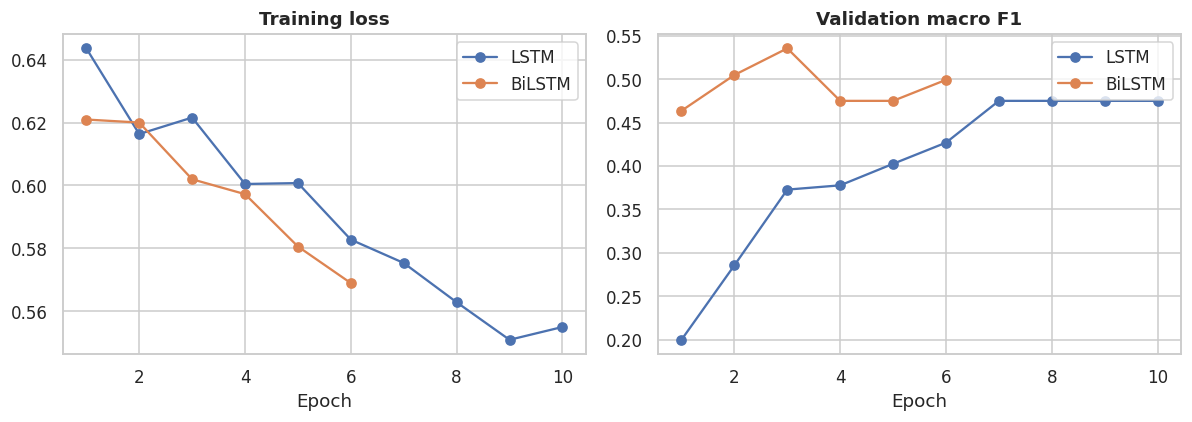

In [35]:
# TRAIN BOTH MODELS
require("train_df", "RecurrentClassifier")


def best_threshold(y_true, prob):
    grid = np.arange(0.05, 0.96, 0.01)
    scores = [f1_score(y_true, (prob >= g).astype(int), average="macro") for g in grid]
    return float(grid[int(np.argmax(scores))])


def train_model(bidirectional, name):
    set_seed()
    model = RecurrentClassifier(len(itos), bidirectional).to(DEVICE)
    n_pos = max(int(train_df["label"].sum()), 1)
    n_neg = max(len(train_df) - n_pos, 1)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(n_neg / n_pos, device=DEVICE))
    opt = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    texts, labels = train_df["text"].tolist(), train_df["label"].tolist()
    best, state, wait, hist = -1.0, None, 0, []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total = 0.0
        for x, lengths, y in make_batches(texts, labels, shuffle=True):
            opt.zero_grad()
            loss = loss_fn(model(x, lengths), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(y)
        vp = predict_proba(model, val_df["text"])
        vf = f1_score(val_df["label"], (vp >= 0.5).astype(int), average="macro")
        hist.append({"epoch": epoch, "train_loss": total / len(texts), "val_macro_f1": vf})
        print(f"{name} epoch {epoch}: train loss {total / len(texts):.4f} | validation macro F1 {vf:.4f}")
        if vf > best:
            best, wait = vf, 0
            state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(state)
    return model, hist


TRAINED, THRESHOLDS, HISTORY = {}, {}, {}
for bidirectional, name in [(False, "LSTM"), (True, "BiLSTM")]:
    TRAINED[name], HISTORY[name] = train_model(bidirectional, name)
    THRESHOLDS[name] = best_threshold(val_df["label"], predict_proba(TRAINED[name], val_df["text"]))
    print(f"{name}: threshold chosen on validation = {THRESHOLDS[name]:.2f}\n")


@figure("08_training_curves")
def _fig_training():
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, h in HISTORY.items():
        h = pd.DataFrame(h)
        axes[0].plot(h["epoch"], h["train_loss"], marker="o", label=name)
        axes[1].plot(h["epoch"], h["val_macro_f1"], marker="o", label=name)
    axes[0].set_title("Training loss")
    axes[1].set_title("Validation macro F1")
    for a in axes:
        a.set_xlabel("Epoch")
        a.legend()


FIG_FUNCS["08_training_curves"]()

## 9.4 Held-out test on your datasets
The only time the test split is read. This tells you how good the models are on text like their training data, before the domain shift to interviews.

,accuracy,precision,recall,macro_f1,auc
LSTM,0.558,0.125,0.077,0.401,0.436
BiLSTM,0.698,0.000,0.000,0.411,0.290


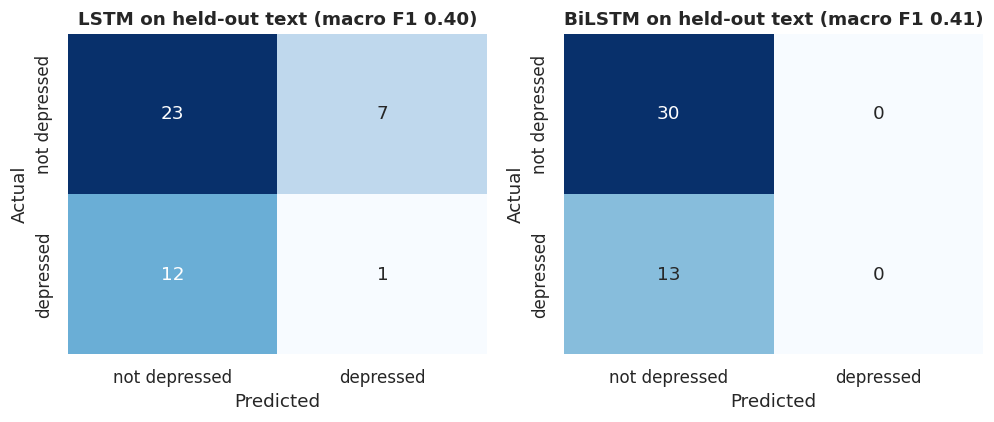

In [36]:
# HELD-OUT TEST SPLIT, READ ONCE
require("TRAINED", "THRESHOLDS")
HELDOUT = {}
for name, model in TRAINED.items():
    prob = predict_proba(model, test_df["text"])
    pred = (prob >= THRESHOLDS[name]).astype(int)
    y = test_df["label"].to_numpy()
    HELDOUT[name] = {"y": y, "prob": prob, "pred": pred, "cm": confusion_matrix(y, pred),
                     "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred),
                     "recall": recall_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
                     "auc": roc_auc_score(y, prob)}
HELDOUT_TABLE = pd.DataFrame({k: {m: v[m] for m in ["accuracy", "precision", "recall", "macro_f1", "auc"]} for k, v in HELDOUT.items()}).T
display(HELDOUT_TABLE.round(3))


@figure("09_heldout_confusion")
def _fig_cm():
    fig, axes = plt.subplots(1, len(HELDOUT), figsize=(4.6 * len(HELDOUT), 4))
    for ax, (name, r) in zip(np.atleast_1d(axes), HELDOUT.items()):
        sns.heatmap(r["cm"], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=["not depressed", "depressed"], yticklabels=["not depressed", "depressed"])
        ax.set_title(f"{name} on held-out text (macro F1 {r['macro_f1']:.2f})")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")


FIG_FUNCS["09_heldout_confusion"]()

# 10. Pretrained models
Three models used as they are, with no fitting and no threshold tuning: DepRoBERTa (fine-tuned on depression posts), a RoBERTa sentiment model (probability of negative tone), and BART zero-shot.

In [40]:
# SCORE EVERY INTERVIEW CHUNK WITH THE PRETRAINED MODELS
require("CHUNKS")
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

DEV = "cuda" if torch.cuda.is_available() else "cpu"


@torch.no_grad()
def hf_probs(model_name, texts, target_fn, batch=16):
    tok = AutoTokenizer.from_pretrained(model_name)
    mdl = AutoModelForSequenceClassification.from_pretrained(model_name).to(DEV).eval()
    id2label = {int(k): v for k, v in mdl.config.id2label.items()}
    print(model_name, "labels:", id2label)
    out = []
    for s in range(0, len(texts), batch):
        enc = tok(texts[s:s + batch], padding=True, truncation=True, max_length=256, return_tensors="pt").to(DEV)
        out.append(target_fn(torch.softmax(mdl(**enc).logits, dim=-1).cpu().numpy(), id2label))
    del mdl
    if DEV == "cuda":
        torch.cuda.empty_cache()
    return np.concatenate(out)


def deproberta_target(p, id2label):
    idx = next((i for i, l in id2label.items() if "not" in l.lower()), 0)
    return 1.0 - p[:, idx]


def negative_target(p, id2label):
    idx = next(i for i, l in id2label.items() if "neg" in l.lower())
    return p[:, idx]


texts = CHUNKS["text"].tolist()
PRETRAINED = {}
PRETRAINED["DepRoBERTa"] = hf_probs("rafalposwiata/deproberta-large-depression", texts, deproberta_target)
PRETRAINED["RoBERTa sentiment"] = hf_probs("cardiffnlp/twitter-roberta-base-sentiment-latest", texts, negative_target)

zs_chunks = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=0 if DEV == "cuda" else -1)
zs_labels = ["depressed and hopeless", "content and doing fine"]
zs_out = zs_chunks(texts, candidate_labels=zs_labels, hypothesis_template="The person speaking is {}.", batch_size=8)
PRETRAINED["BART zero-shot"] = np.array([r["scores"][r["labels"].index(zs_labels[0])] for r in zs_out])
del zs_chunks
print({k: v.shape for k, v in PRETRAINED.items()})

config.json:   0%|          | 0.00/924 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

... (5 outputs left out)

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


cardiffnlp/twitter-roberta-base-sentiment-latest labels: {0: 'negative', 1: 'neutral', 2: 'positive'}


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

{'DepRoBERTa': (45,), 'RoBERTa sentiment': (45,), 'BART zero-shot': (45,)}


# 11. Compare the five models on the interviews
The verdict rule is fixed in advance: a session is called depressed when the mean chunk probability reaches the model's threshold. Trained models use their validation threshold, pretrained models use one half.

,model,session,true_label,mean_prob,share_chunks_flagged,threshold,verdict,correct
0,LSTM,303,0,0.504,0.182,0.54,0,True
1,LSTM,319,1,0.472,0.167,0.54,0,False
2,BiLSTM,303,0,0.504,0.030,0.56,0,True
3,BiLSTM,319,1,0.492,0.000,0.56,0,False
4,DepRoBERTa,303,0,0.127,0.030,0.50,0,True
5,DepRoBERTa,319,1,0.297,0.167,0.50,0,False
6,RoBERTa sentiment,303,0,0.170,0.152,0.50,0,True
7,RoBERTa sentiment,319,1,0.284,0.250,0.50,0,False
8,BART zero-shot,303,0,0.357,0.364,0.50,0,True
9,BART zero-shot,319,1,0.502,0.500,0.50,1,True


session,303,319,gap_depressed_minus_not,all_correct
model,,,,
DepRoBERTa,0.127,0.297,0.170,False
BART zero-shot,0.357,0.502,0.145,True
RoBERTa sentiment,0.170,0.284,0.114,False
BiLSTM,0.504,0.492,-0.012,False
LSTM,0.504,0.472,-0.033,False


With two sessions a coin flip gets both right a quarter of the time, so read the gap, not only the verdict.


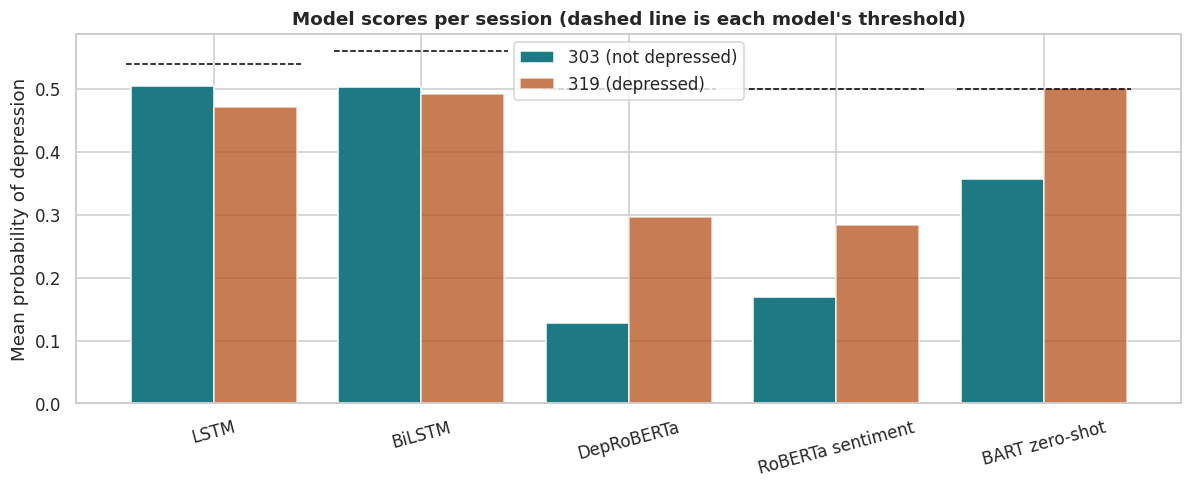

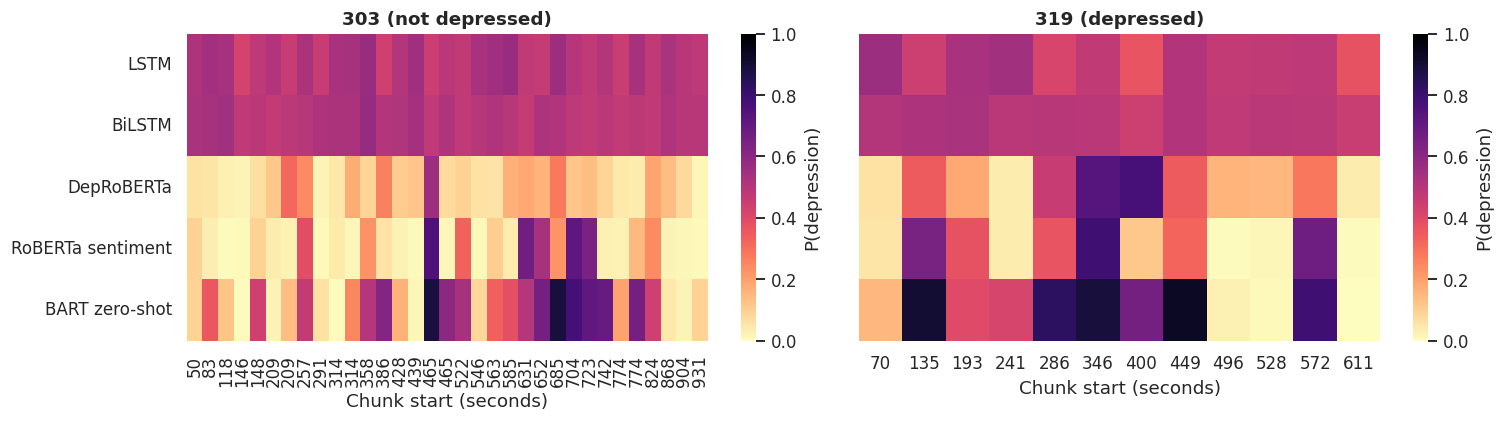

In [41]:
# SCORE INTERVIEW CHUNKS AND COMPARE
require("CHUNKS", "TRAINED", "PRETRAINED")
SCORES = {name: predict_proba(m, CHUNKS["text"]) for name, m in TRAINED.items()}
SCORES.update(PRETRAINED)
CUT = {name: THRESHOLDS[name] for name in TRAINED}
CUT.update({name: 0.5 for name in PRETRAINED})
for name, arr in SCORES.items():
    CHUNKS[name] = arr

rows = []
for name in SCORES:
    for sid, truth in SESSIONS.items():
        p = CHUNKS.loc[CHUNKS["session"] == sid, name].to_numpy()
        verdict = int(p.mean() >= CUT[name])
        rows.append({"model": name, "session": sid, "true_label": truth, "mean_prob": p.mean(),
                     "share_chunks_flagged": (p >= CUT[name]).mean(), "threshold": CUT[name],
                     "verdict": verdict, "correct": verdict == truth})
SUMMARY = pd.DataFrame(rows)
display(SUMMARY.round(3))

PIVOT = SUMMARY.pivot(index="model", columns="session", values="mean_prob")
if 0 in SESSIONS.values() and 1 in SESSIONS.values():
    neg = [s for s, l in SESSIONS.items() if l == 0]
    pos = [s for s, l in SESSIONS.items() if l == 1]
    PIVOT["gap_depressed_minus_not"] = PIVOT[pos].mean(axis=1) - PIVOT[neg].mean(axis=1)
PIVOT["all_correct"] = SUMMARY.groupby("model")["correct"].all()
display(PIVOT.sort_values(PIVOT.columns[-2], ascending=False).round(3))
print("With two sessions a coin flip gets both right a quarter of the time, so read the gap, not only the verdict.")


@figure("10_model_comparison")
def _fig_models():
    names = list(SCORES)
    x = np.arange(len(names))
    k = len(SESSIONS)
    width = 0.8 / k
    fig, ax = plt.subplots(figsize=(11, 4.6))
    for j, sid in enumerate(SESSIONS):
        vals = [CHUNKS.loc[CHUNKS["session"] == sid, n].mean() for n in names]
        ax.bar(x + (j - (k - 1) / 2) * width, vals, width, color=LABEL_COLORS[SESSIONS[sid]],
               alpha=1.0 if j == 0 else 0.75, label=sess_label(sid), edgecolor="white")
    for i, n in enumerate(names):
        ax.hlines(CUT[n], i - 0.42, i + 0.42, colors="black", linestyles="dashed", lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=15)
    ax.set_ylabel("Mean probability of depression")
    ax.set_title("Model scores per session (dashed line is each model's threshold)")
    ax.legend()


@figure("11_chunk_heatmap")
def _fig_chunk_heat():
    fig, axes = plt.subplots(1, len(SESSIONS), figsize=(7 * len(SESSIONS), 4), sharey=True)
    for ax, sid in zip(np.atleast_1d(axes), SESSIONS):
        sub = CHUNKS[CHUNKS["session"] == sid]
        sns.heatmap(sub[list(SCORES)].T, ax=ax, cmap="magma_r", vmin=0, vmax=1, cbar_kws={"label": "P(depression)"},
                    xticklabels=[f"{int(s)}" for s in sub["start_sec"]])
        ax.set_title(sess_label(sid))
        ax.set_xlabel("Chunk start (seconds)")


FIG_FUNCS["10_model_comparison"]()
FIG_FUNCS["11_chunk_heatmap"]()

# 12. Report figures and tables
Draws every figure from the blocks you have run, saves each as a high-resolution PNG, writes the tables as CSV and zips everything for download.

Drawing 08_training_curves


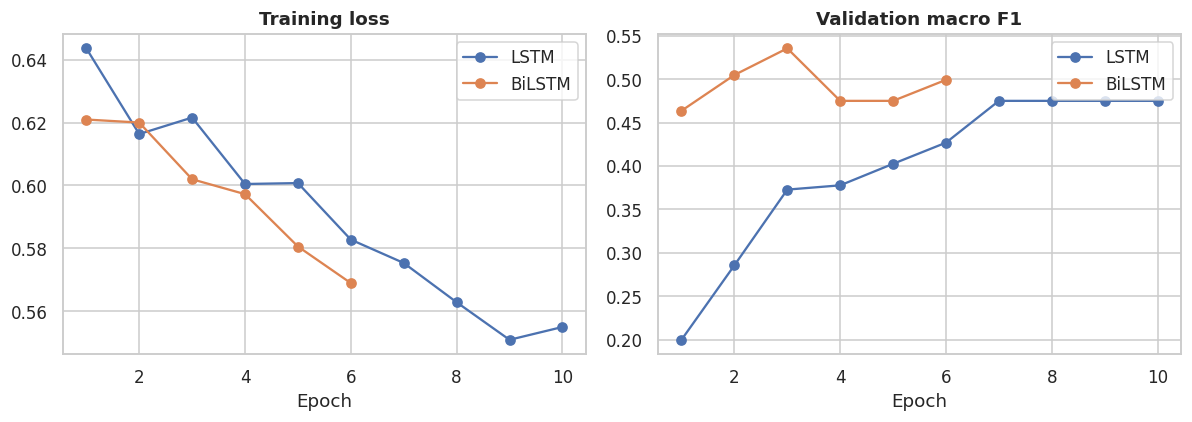

Drawing 09_heldout_confusion


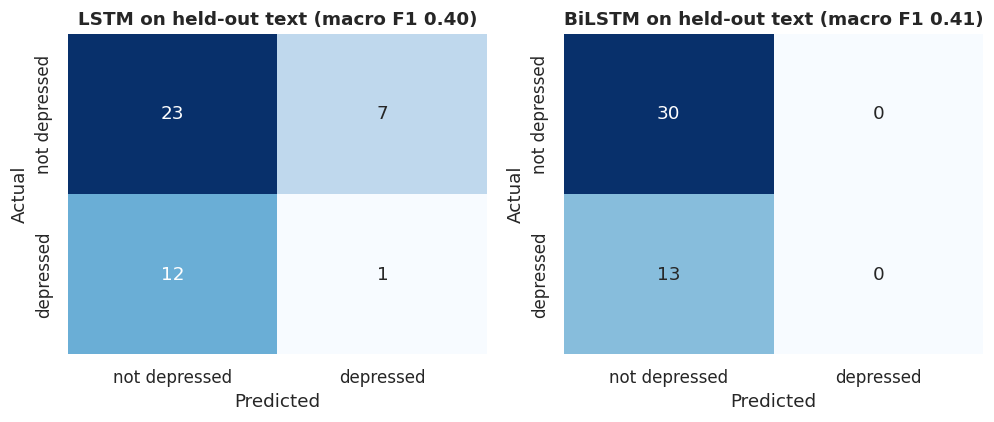

Drawing 10_model_comparison


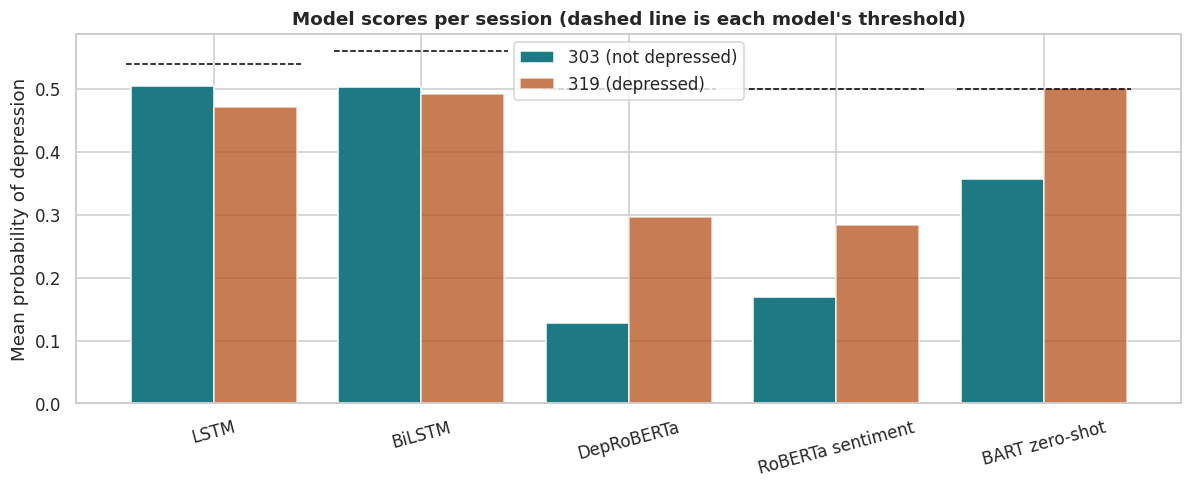

Drawing 11_chunk_heatmap


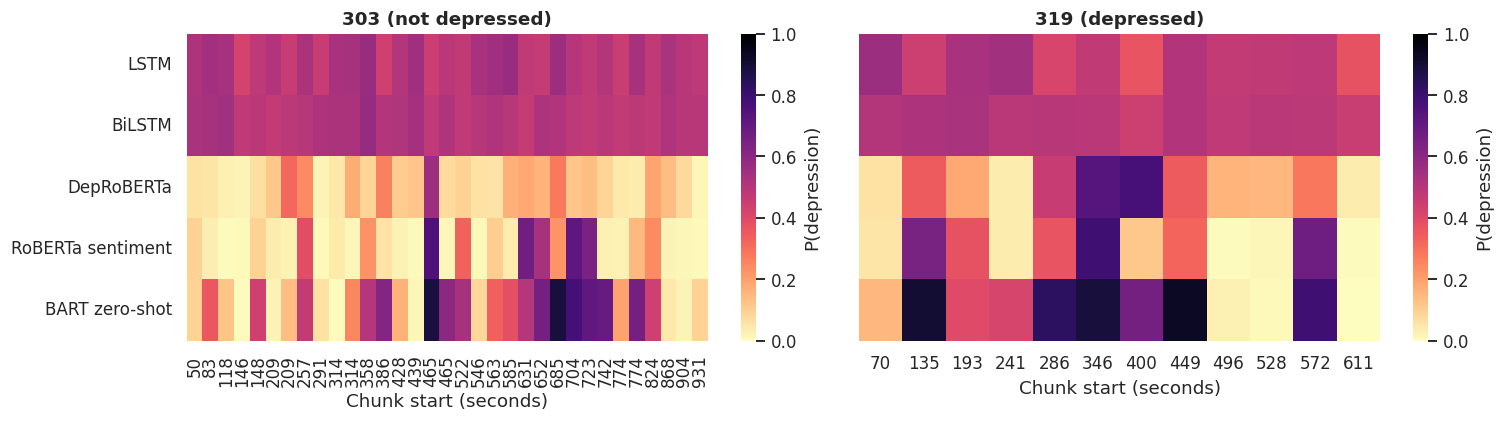

Saved 12 figures and 7 tables to /content/report_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
# REGENERATE ALL REPORT FIGURES, SAVE TABLES, ZIP
if len(FIG_FUNCS) == 0:
    raise RuntimeError("No figures registered yet. Run at least one analysis block first.")

for name in sorted(FIG_FUNCS):
    print("Drawing", name)
    FIG_FUNCS[name]()

TABLE_DIR = FIG_DIR / "tables"
TABLE_DIR.mkdir(exist_ok=True)
feature_table().round(4).to_csv(TABLE_DIR / "session_features.csv")
for name in ["QA", "SUMMARY", "PIVOT", "HELDOUT_TABLE", "SYMPTOM_TABLE", "overview"]:
    obj = globals().get(name)
    if isinstance(obj, (pd.DataFrame, pd.Series)):
        obj.round(4).to_csv(TABLE_DIR / f"{name.lower()}.csv")

zip_path = FIG_DIR.parent / "report_figures.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(FIG_DIR.rglob("*")):
        if p.is_file():
            z.write(p, p.relative_to(FIG_DIR))
print("Saved", len(list(FIG_DIR.glob("*.png"))), "figures and", len(list(TABLE_DIR.glob("*.csv"))), "tables to", zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    pass